In [5]:
#Import essential libraries needed for segmentation process.

import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split



In [6]:

#Finding and setting up the dataset path

import os

INPUT_ROOT = "/kaggle/input"
print("Datasets in /kaggle/input:")
print(os.listdir(INPUT_ROOT))

# Try to automatically find the folder whose name contains "segmentation"
candidates = [d for d in os.listdir(INPUT_ROOT) if "segmentation" in d.lower()]
print("\nCandidates:", candidates)

DATA_ROOT = os.path.join(INPUT_ROOT, candidates[0])  # use the first match
print("\nUsing DATA_ROOT =", DATA_ROOT)
print("Contents of DATA_ROOT:", os.listdir(DATA_ROOT))


Datasets in /kaggle/input:
['segmentation-task']

Candidates: ['segmentation-task']

Using DATA_ROOT = /kaggle/input/segmentation-task
Contents of DATA_ROOT: ['segmentation_task']


In [7]:
#Loading and preprocessing image data with canny edge detection


IMG_HEIGHT, IMG_WIDTH = 256, 256

train_img_dir  = "/kaggle/input/segmentation-task/segmentation_task/train/images"
train_mask_dir = "/kaggle/input/segmentation-task/segmentation_task/train/masks"
test_img_dir   = "/kaggle/input/segmentation-task/segmentation_task/test/images"
test_mask_dir  = "/kaggle/input/segmentation-task/segmentation_task/test/masks"

def load_with_canny(img_dir, mask_dir):
    images = []
    masks = []

    img_files = sorted([f for f in os.listdir(img_dir) if f.lower().endswith((".png", ".jpg", ".jpeg"))])
    mask_files = sorted([f for f in os.listdir(mask_dir) if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    for img_name, mask_name in zip(img_files, mask_files):

        img_path = os.path.join(img_dir, img_name)
        mask_path = os.path.join(mask_dir, mask_name)

        # Load grayscale image
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Resize
        img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
        mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)

        # Normalize image
        img_norm = img.astype(np.float32) / 255.0

        # Generate canny edges
        edges = cv2.Canny(img, threshold1=60, threshold2=120)
        edges = edges.astype(np.float32) / 255.0

        # Stack channels: (H, W, 2)
        img_2ch = np.stack([img_norm, edges], axis=-1)

        # Mask: binary (H, W, 1)
        mask_bin = (mask > 0).astype(np.float32)
        mask_bin = np.expand_dims(mask_bin, axis=-1)

        images.append(img_2ch)
        masks.append(mask_bin)

    return np.array(images), np.array(masks)

print("Loading training set...")
X_train, Y_train = load_with_canny(train_img_dir, train_mask_dir)
print("Training shape:", X_train.shape, Y_train.shape)

print("Loading test set...")
X_test, Y_test = load_with_canny(test_img_dir, test_mask_dir)
print("Test shape:", X_test.shape, Y_test.shape)


Loading training set...
Training shape: (3933, 256, 256, 2) (3933, 256, 256, 1)
Loading test set...
Test shape: (860, 256, 256, 2) (860, 256, 256, 1)


In [8]:
#Splitting training data into training and validation sets 

X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_train, Y_train, test_size=0.15, random_state=42
)

print("Train subset:", X_tr.shape, Y_tr.shape)
print("Val subset  :", X_val.shape, Y_val.shape)


Train subset: (3343, 256, 256, 2) (3343, 256, 256, 1)
Val subset  : (590, 256, 256, 2) (590, 256, 256, 1)


In [11]:
#Importing TensorFlow and Keras Components
#Defining custom metrics and loss function for segmentation

import tensorflow as tf
from tensorflow.keras import layers, Model

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# For single-image checks (NumPy)
import numpy as np
def dice_score_np(y_true, y_pred, smooth=1e-8):
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)
    inter = np.logical_and(y_true, y_pred).sum()
    return (2 * inter + smooth) / (y_true.sum() + y_pred.sum() + smooth)


In [12]:
#Creates the convolutional block (Conv2D, BatchNorm, ReLU X 2)
#Builds the U-NET Model architecture 


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def build_unet(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32);  p1 = layers.MaxPool2D()(c1)
    c2 = conv_block(p1,     64);  p2 = layers.MaxPool2D()(c2)
    c3 = conv_block(p2,    128);  p3 = layers.MaxPool2D()(c3)
    c4 = conv_block(p3,    256);  p4 = layers.MaxPool2D()(c4)

    # Bottleneck
    b  = conv_block(p4,    512)

    # Decoder
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c8)

    model = Model(inputs, outputs, name="UNet_Canny2Channel")
    return model

input_shape = X_tr.shape[1:]   # (256, 256, 2)
unet = build_unet(input_shape)
unet.summary()


I0000 00:00:1765297309.457291      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1765297309.457856      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "UNet_Canny2Channel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        608 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,585 (29.65 MB)

 Trainable params: 7,765,697 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [13]:
#Compiles the U-Net Model 
#Compiles the Adam Optimizer, Dice loss, Dice Coefficient and Accuracy as Metrics
#set training parameters epoch = 20, batch size = 4
#sets up callbacks model check point and early stopping
#Saves the best model based on validation Dice score
#Stops training if no improvement for 5 epochs


unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[dice_coef, "accuracy"]
)

EPOCHS = 20
BATCH_SIZE = 4   # can try 8 later if memory allows

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "unet_canny_best.h5",
    monitor="val_dice_coef",
    mode="max",
    save_best_only=True,
    verbose=1
)

earlystop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_dice_coef",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = unet.fit(
    X_tr, Y_tr,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[checkpoint_cb, earlystop_cb]
)


Epoch 1/20


I0000 00:00:1765297370.915455     117 service.cc:148] XLA service 0x7b1688152850 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765297370.916344     117 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1765297370.916365     117 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1765297372.574271     117 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1765297379.302180     117 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765297379.515763     117 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/836 ━━━━━━━━━━━━━━━━━━━━ 7:21:58 32s/step - accuracy: 0.6062 - dice_coef: 0.0377 - loss: 0.9623

I0000 00:00:1765297391.516150     117 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


835/836 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8580 - dice_coef: 0.1461 - loss: 0.8539

E0000 00:00:1765297476.811627     117 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765297477.038862     117 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (6 outputs left out)

836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9926 - dice_coef: 0.7664 - loss: 0.2336 - val_accuracy: 0.9915 - val_dice_coef: 0.7250 - val_loss: 0.2753
Epoch 7/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9925 - dice_coef: 0.7695 - loss: 0.2305
Epoch 7: val_dice_coef improved from 0.72497 to 0.74404, saving model to unet_canny_best.h5


836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9925 - dice_coef: 0.7695 - loss: 0.2305 - val_accuracy: 0.9917 - val_dice_coef: 0.7440 - val_loss: 0.2562
Epoch 8/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9929 - dice_coef: 0.7776 - loss: 0.2224
Epoch 8: val_dice_coef did not improve from 0.74404
836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9929 - dice_coef: 0.7776 - loss: 0.2224 - val_accuracy: 0.9915 - val_dice_coef: 0.7230 - val_loss: 0.2772
Epoch 9/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9931 - dice_coef: 0.7903 - loss: 0.2097
Epoch 9: val_dice_coef did not improve from 0.74404
836/836 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9931 - dice_coef: 0.7903 - loss: 0.2097 - val_accuracy: 0.9918 - val_dice_coef: 0.7397 - val_loss: 0.2605
Epoch 10/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9936 - dice_coef: 0.8083 - loss: 0.1917
Epoch 10: val_dice_coef did not improve from 0.74404
836/836 ━━━━━━━━━━━━━━━━━━━━ 

836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9937 - dice_coef: 0.8050 - loss: 0.1950 - val_accuracy: 0.9923 - val_dice_coef: 0.7525 - val_loss: 0.2476
Epoch 12/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9936 - dice_coef: 0.8046 - loss: 0.1954
Epoch 12: val_dice_coef improved from 0.75248 to 0.76046, saving model to unet_canny_best.h5


836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9936 - dice_coef: 0.8046 - loss: 0.1954 - val_accuracy: 0.9925 - val_dice_coef: 0.7605 - val_loss: 0.2398
Epoch 13/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9932 - dice_coef: 0.8019 - loss: 0.1981
Epoch 13: val_dice_coef did not improve from 0.76046
836/836 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9932 - dice_coef: 0.8019 - loss: 0.1981 - val_accuracy: 0.9922 - val_dice_coef: 0.7524 - val_loss: 0.2479
Epoch 14/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9941 - dice_coef: 0.8210 - loss: 0.1790
Epoch 14: val_dice_coef did not improve from 0.76046
836/836 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9941 - dice_coef: 0.8209 - loss: 0.1791 - val_accuracy: 0.9923 - val_dice_coef: 0.7375 - val_loss: 0.2626
Epoch 15/20
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9942 - dice_coef: 0.8283 - loss: 0.1717
Epoch 15: val_dice_coef did not improve from 0.76046
836/836 ━━━━━━━━━━━━━━━━━

In [14]:
test_results = unet.evaluate(X_test, Y_test, batch_size=4)

print("Test loss    :", test_results[0])
print("Test Dice    :", test_results[1])
print("Test accuracy:", test_results[2])


215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9884 - dice_coef: 0.6614 - loss: 0.3386
Test loss    : 0.23509079217910767
Test Dice    : 0.7649092674255371
Test accuracy: 0.991645336151123


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Image 10 Dice: 8.264462809234343e-11


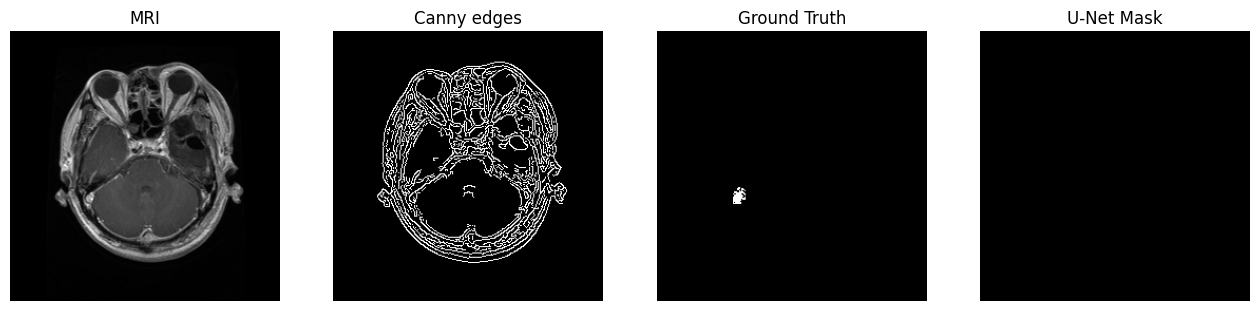

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Image 25 Dice: 0.07845366686140733


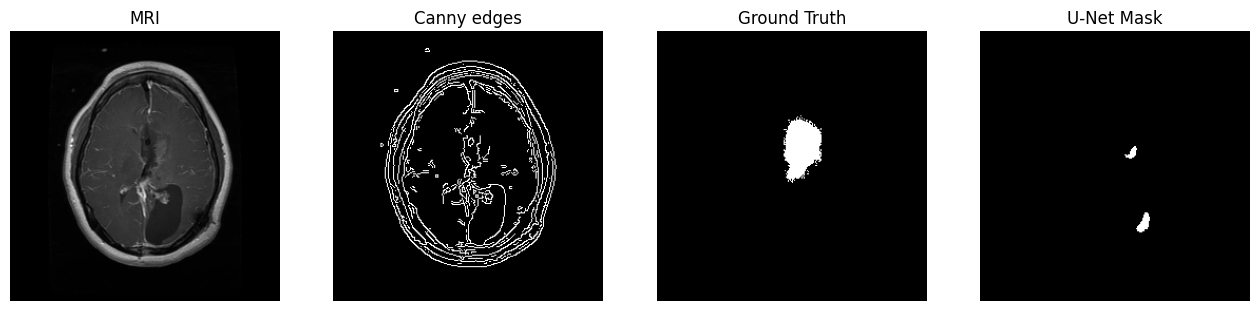

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Image 50 Dice: 0.08226221079953654


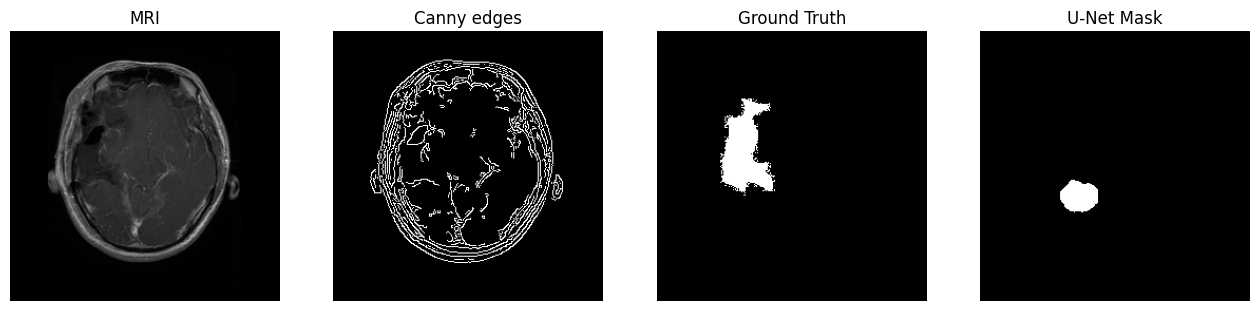

In [17]:
#Test Model on a few images

import matplotlib.pyplot as plt

def show_example(idx):
    img_2ch = X_test[idx]       # (256,256,2)
    gt      = Y_test[idx, ..., 0]  # (256,256)

    # Split channels
    img_orig  = img_2ch[..., 0]
    img_edges = img_2ch[..., 1]

    # Predict
    pred = unet.predict(img_2ch[np.newaxis, ...])[0, ..., 0]
    pred_bin = (pred > 0.5).astype("uint8")

    d = dice_score_np(gt, pred_bin)
    print(f"Image {idx} Dice:", d)

    plt.figure(figsize=(16,4))
    plt.subplot(1,4,1); plt.imshow(img_orig, cmap="gray");  plt.title("MRI");           plt.axis("off")
    plt.subplot(1,4,2); plt.imshow(img_edges, cmap="gray"); plt.title("Canny edges");   plt.axis("off")
    plt.subplot(1,4,3); plt.imshow(gt, cmap="gray");        plt.title("Ground Truth");  plt.axis("off")
    plt.subplot(1,4,4); plt.imshow(pred_bin, cmap="gray");  plt.title("U-Net Mask");    plt.axis("off")
    plt.show()

# Try a few examples:
show_example(10)
show_example(25)
show_example(50)


In [18]:
#Start the data augmentation process.
#Retrain X_train and Y_train again

import os, cv2, numpy as np

IMG_HEIGHT, IMG_WIDTH = 256, 256

DATA_ROOT = "/kaggle/input/segmentation-task/segmentation_task"
train_img_dir  = os.path.join(DATA_ROOT, "train", "images")
train_mask_dir = os.path.join(DATA_ROOT, "train", "masks")
test_img_dir   = os.path.join(DATA_ROOT, "test", "images")
test_mask_dir  = os.path.join(DATA_ROOT, "test", "masks")

print("Train images:", len(os.listdir(train_img_dir)))
print("Train masks :", len(os.listdir(train_mask_dir)))
print("Test images :", len(os.listdir(test_img_dir)))
print("Test masks  :", len(os.listdir(test_mask_dir)))

def load_with_canny(img_dir, mask_dir, img_h=256, img_w=256):
    images = []
    masks  = []

    img_files  = sorted([f for f in os.listdir(img_dir)  if f.lower().endswith((".png", ".jpg", ".jpeg"))])
    mask_files = sorted([f for f in os.listdir(mask_dir) if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    for img_name, mask_name in zip(img_files, mask_files):
        img_path  = os.path.join(img_dir, img_name)
        mask_path = os.path.join(mask_dir, mask_name)

        # 1) load grayscale MRI and mask
        img  = cv2.imread(img_path,  cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None:
            continue

        # 2) resize
        img  = cv2.resize(img,  (img_w, img_h))
        mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)

        # 3) Normalize original image
        img_norm = img.astype("float32") / 255.0
        
        # 4) canny edges on MRI
        edges = cv2.Canny(img, 50, 150).astype("float32") / 255.0
        
        # 5) Stack original image + edges = 2 channels
        img_2ch = np.stack([img_norm, edges], axis=-1)  # ← FIX: 2 CHANNELS!
        
        # 6) binarize mask
        mask_bin = (mask > 0).astype("float32")

        images.append(img_2ch)  # ← Now has 2 channels
        masks.append(mask_bin)

    X = np.array(images)   # (N, H, W, 2) ← Now 2 channels!
    Y = np.array(masks)[..., np.newaxis]  # (N, H, W, 1)

    print("Loaded:", X.shape, Y.shape)
    return X, Y
      

print("\nLoading training set...")
X_train, Y_train = load_with_canny(train_img_dir, train_mask_dir)

print("\nLoading test set...")
X_test, Y_test = load_with_canny(test_img_dir, test_mask_dir)

print("\nFinal shapes:")
print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "Y_test :", Y_test.shape)


Train images: 3933
Train masks : 3933
Test images : 860
Test masks  : 860

Loading training set...
Loaded: (3933, 256, 256, 2) (3933, 256, 256, 1)

Loading test set...
Loaded: (860, 256, 256, 2) (860, 256, 256, 1)

Final shapes:
X_train: (3933, 256, 256, 2) Y_train: (3933, 256, 256, 1)
X_test : (860, 256, 256, 2) Y_test : (860, 256, 256, 1)


In [19]:
#Split the data

from sklearn.model_selection import train_test_split

X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_train, Y_train,
    test_size=0.15,
    random_state=42
)

print("Train subset:", X_tr.shape, Y_tr.shape)
print("Val subset  :", X_val.shape, Y_val.shape)
print("Test subset :", X_test.shape, Y_test.shape)


Train subset: (3343, 256, 256, 2) (3343, 256, 256, 1)
Val subset  : (590, 256, 256, 2) (590, 256, 256, 1)
Test subset : (860, 256, 256, 2) (860, 256, 256, 1)


In [21]:
#mild augmmentation
#creating two seperate generators with mild augmentation

from tensorflow.keras.preprocessing.image import ImageDataGenerator

seed = 42

image_datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    fill_mode="nearest"
)

mask_datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    fill_mode="nearest"
)


In [23]:
#Build a paired generator
#creates paired generator for images and masks
#ensures same transformation is applied to images and masks
#creates infinite generator for training

def make_generator(X, Y, batch_size=4, seed=42):
    img_gen  = image_datagen.flow(X, batch_size=batch_size, seed=seed, shuffle=True)
    mask_gen = mask_datagen.flow(Y, batch_size=batch_size, seed=seed, shuffle=True)
    while True:
        x = next(img_gen)
        y = next(mask_gen)
        yield x, y


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:619: UserWarning: NumpyArrayIterator is set to use the data format convention "channels_last" (channels on axis 3), i.e. expected either 1, 3, or 4 channels on axis 3. However, it was passed an array with shape (3343, 256, 256, 2) (2 channels).
  warnings.warn(


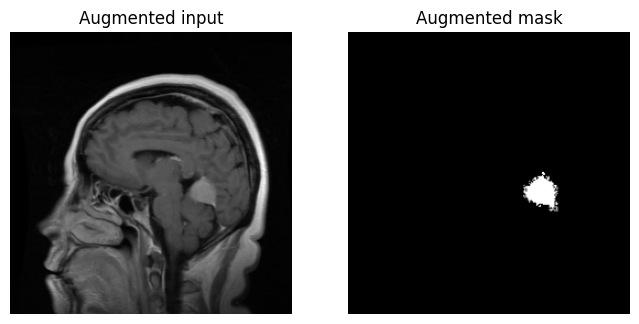

In [24]:
#Sanity Check
#Let's check one augmented pair and see how it goes.

import matplotlib.pyplot as plt

train_gen = make_generator(X_tr, Y_tr, batch_size=1, seed=seed)
x_batch, y_batch = next(train_gen)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(x_batch[0,...,0], cmap="gray"); plt.title("Augmented input"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(y_batch[0,...,0], cmap="gray"); plt.title("Augmented mask"); plt.axis("off")
plt.show()


In [27]:
#Train the U-NET model with augmentation 

#Sets training parameters
#creates augmented generators
#calculates steps per epoch


input_shape = X_tr.shape[1:]   # (256, 256, 2)
unet = build_unet(input_shape)
unet.summary()

# 2. Compile the model
unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[dice_coef, "accuracy"]
)

BATCH_SIZE = 4
EPOCHS = 20

train_gen = make_generator(X_tr, Y_tr, batch_size=BATCH_SIZE, seed=seed)
val_gen   = make_generator(X_val, Y_val, batch_size=BATCH_SIZE, seed=seed)

steps_train = len(X_tr) // BATCH_SIZE
steps_val   = len(X_val) // BATCH_SIZE

history = unet.fit(
    train_gen,
    steps_per_epoch=steps_train,
    validation_data=val_gen,
    validation_steps=steps_val,
    epochs=EPOCHS
)


Model: "UNet_Canny2Channel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 256, 256,  │        608 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_57[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_54       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_58 (Conv2D)  │ (None, 256, 256,  │      9,248 │ activation_54[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_58[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_55       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 128, 128,  │          0 │ activation_55[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_12… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_59[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_56       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_60 (Conv2D)  │ (None, 128, 128,  │     36,928 │ activation_56[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_60[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_57       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 64, 64,    │          0 │ activation_57[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_61 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_13… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_61[0][0] 

 Total params: 7,771,585 (29.65 MB)

 Trainable params: 7,765,697 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

Epoch 1/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 109s 107ms/step - accuracy: 0.8140 - dice_coef: 0.1209 - loss: 0.8791 - val_accuracy: 0.9752 - val_dice_coef: 0.2734 - val_loss: 0.7266
Epoch 2/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 96s 105ms/step - accuracy: 0.9792 - dice_coef: 0.3521 - loss: 0.6479 - val_accuracy: 0.9869 - val_dice_coef: 0.5182 - val_loss: 0.4818
Epoch 3/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 87s 104ms/step - accuracy: 0.9860 - dice_coef: 0.5811 - loss: 0.4189 - val_accuracy: 0.9874 - val_dice_coef: 0.6255 - val_loss: 0.3745
Epoch 4/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 87s 104ms/step - accuracy: 0.9871 - dice_coef: 0.6686 - loss: 0.3312 - val_accuracy: 0.9876 - val_dice_coef: 0.6898 - val_loss: 0.3094
Epoch 5/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 87s 104ms/step - accuracy: 0.9885 - dice_coef: 0.7230 - loss: 0.2763 - val_accuracy: 0.9879 - val_dice_coef: 0.6881 - val_loss: 0.3119
Epoch 6/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 86s 103ms/step - accuracy: 0.9879 - dice_coef: 0.7279 - loss: 0.2719 - val_accuracy:

In [28]:
#Print the loss test, dice score and accuracy

test_results = unet.evaluate(X_test, Y_test, batch_size=BATCH_SIZE)
print("Test loss    :", test_results[0])
print("Test Dice    :", test_results[1])
print("Test accuracy:", test_results[2])


215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9895 - dice_coef: 0.7061 - loss: 0.2939
Test loss    : 0.20519286394119263
Test Dice    : 0.7948073744773865
Test accuracy: 0.9925942420959473


Random samples: [622 720 638 330 683]
X_test shape: (860, 256, 256, 2)
Y_test shape: (860, 256, 256, 1)


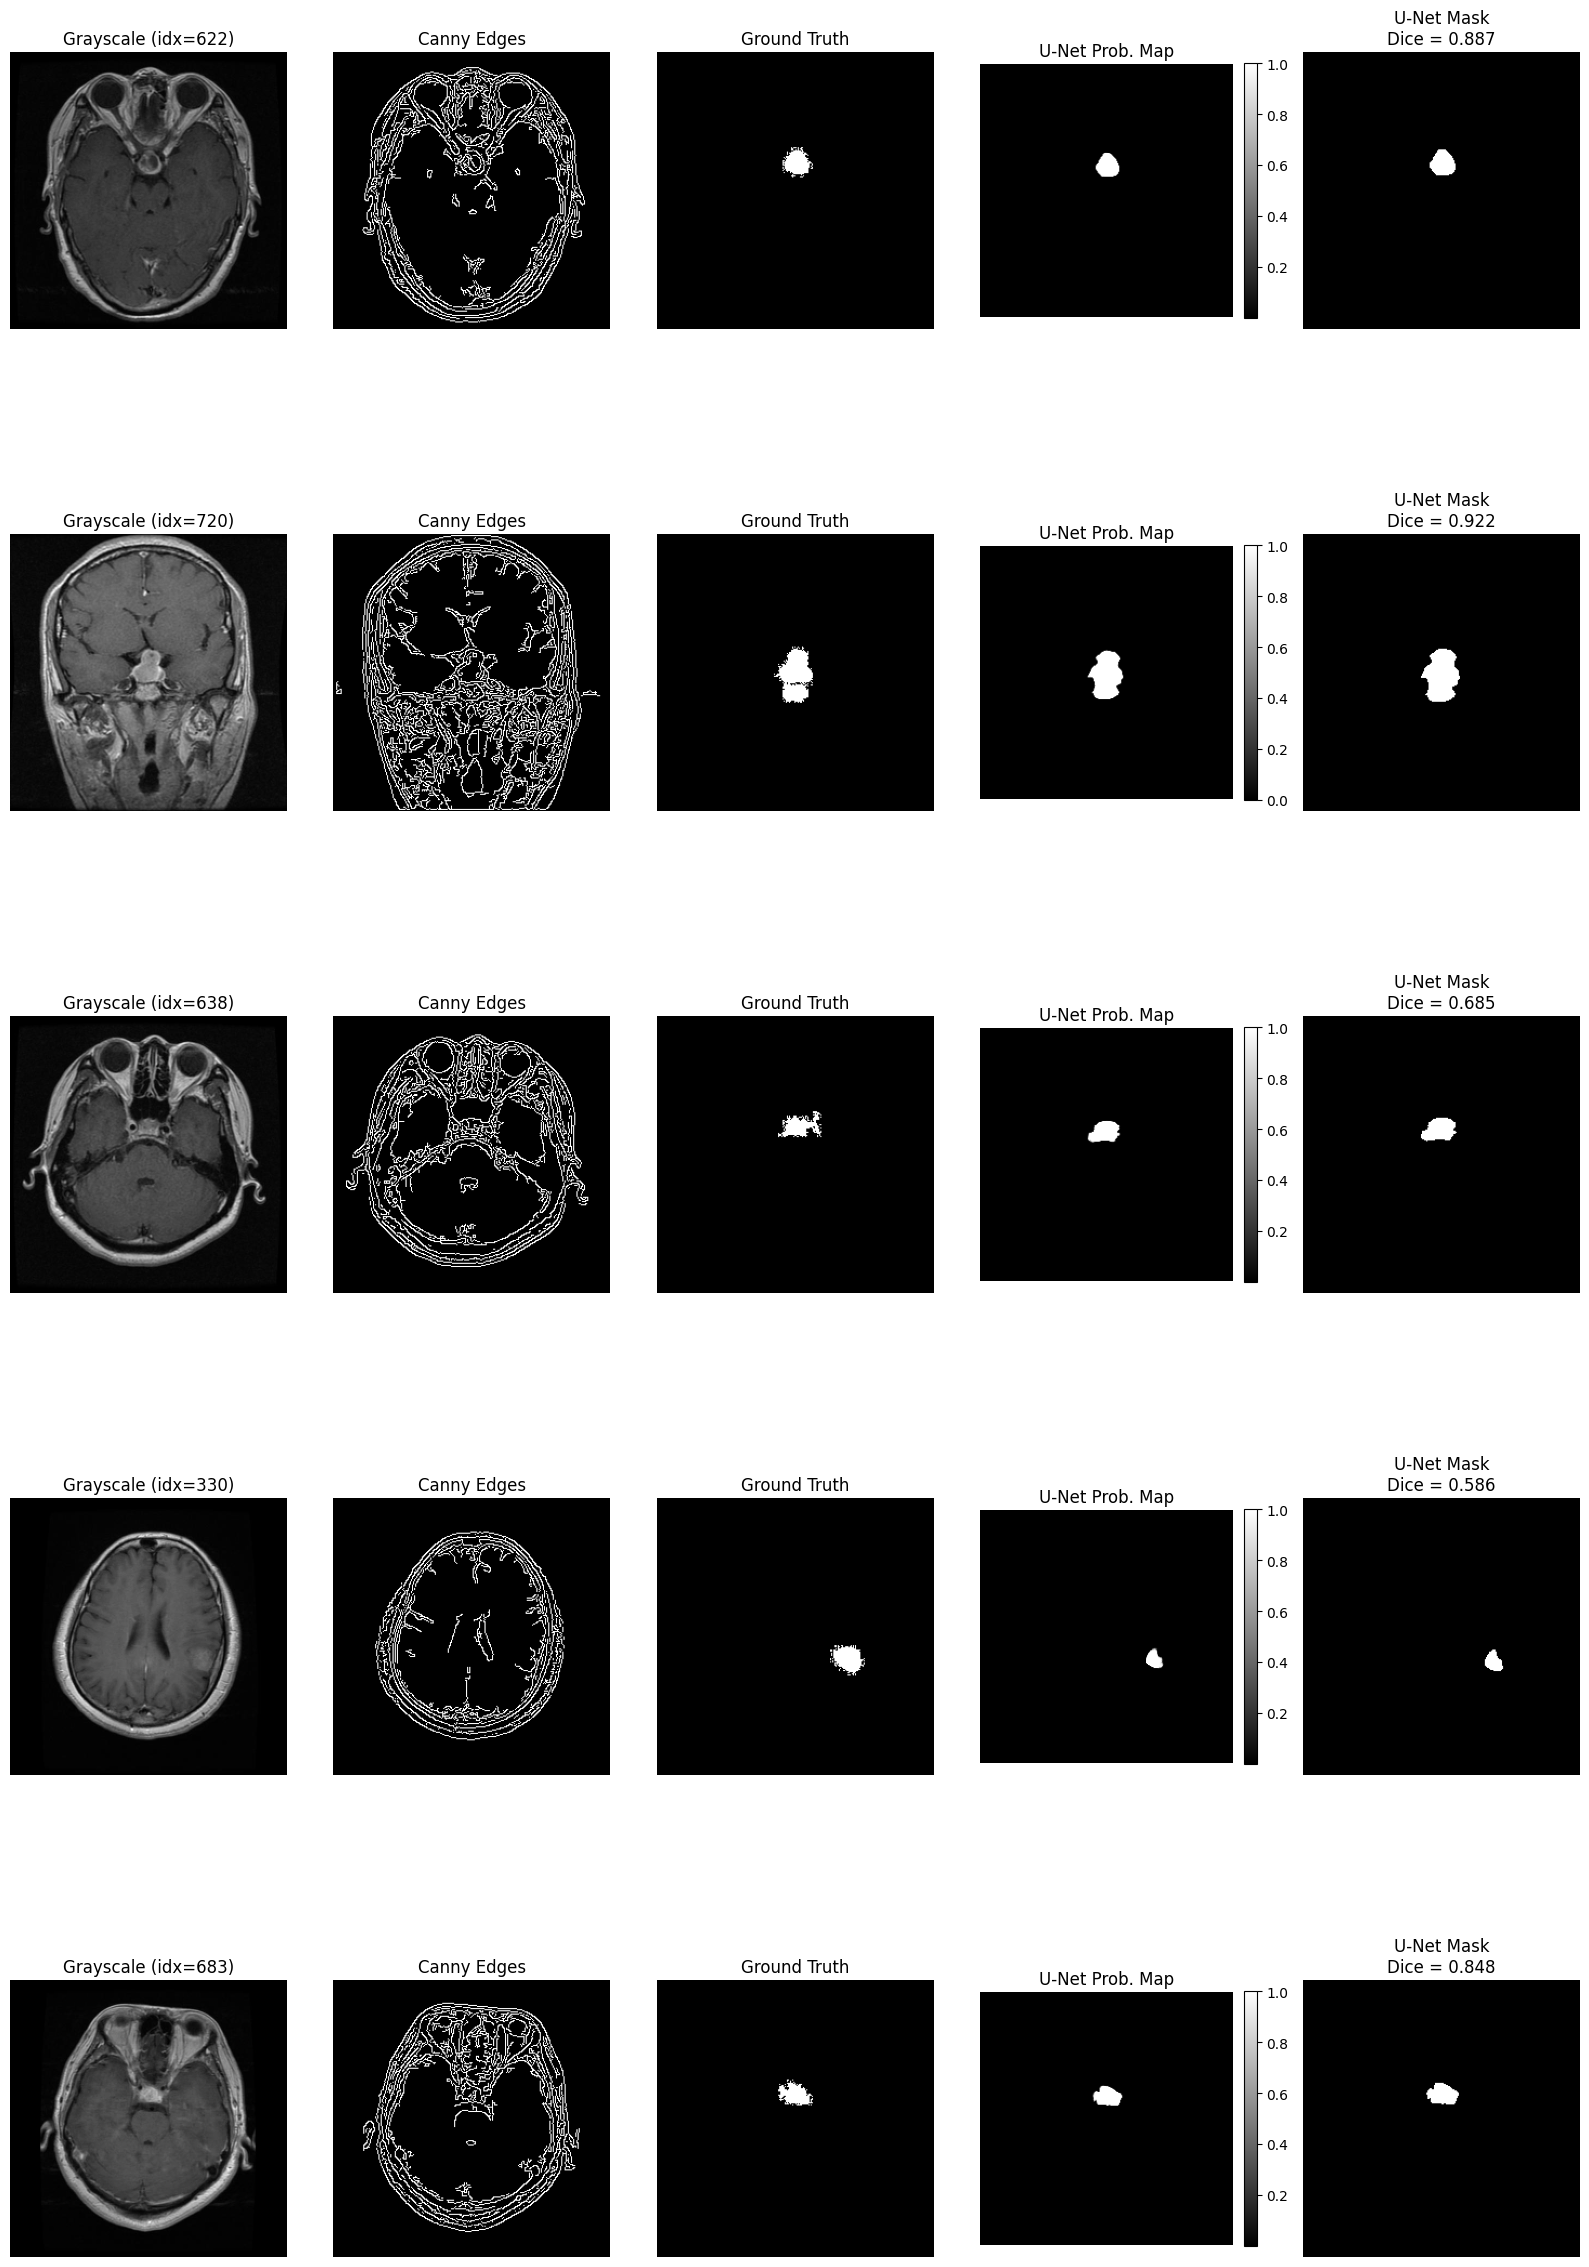


MODEL PERFORMANCE SUMMARY:
Test Dice Coefficient: 0.7762
Test Accuracy: 0.9923
Test Loss: 0.2238

Dice Score Interpretation:
0.0 - 0.3: Poor
0.3 - 0.6: Fair
0.6 - 0.8: Good (Your result: 0.776)
0.8 - 0.9: Very Good
0.9 - 1.0: Excellent


In [30]:
#Lets view on a few random samples

import numpy as np
import matplotlib.pyplot as plt

# Dice metric function
def dice_score_np(y_true, y_pred, eps=1e-8):
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)
    intersection = np.logical_and(y_true, y_pred).sum()
    return (2. * intersection) / (y_true.sum() + y_pred.sum() + eps)

# Number of images to visualize
n_show = 5

# Select random indices
indices = np.random.choice(len(X_test), n_show, replace=False)
print("Random samples:", indices)
print(f"X_test shape: {X_test.shape}")  # Should be (860, 256, 256, 2)
print(f"Y_test shape: {Y_test.shape}")  # Should be (860, 256, 256, 1)

plt.figure(figsize=(16, 5 * n_show))

for i, idx in enumerate(indices):
    # Input (2 channels: grayscale + canny edges) & Ground truth
    img = X_test[idx]        # Shape: (256, 256, 2)
    gt  = Y_test[idx, ..., 0]  # Shape: (256, 256)
    
    # Model prediction
    pred_prob = unet.predict(img[np.newaxis, ...], verbose=0)[0, ..., 0]  # (256,256)
    pred_bin  = (pred_prob > 0.5).astype(np.uint8)
    
    # Dice for the image
    dice = dice_score_np(gt, pred_bin)
    
    # Starting position for this row (now 5 columns)
    r = i * 5
    
    # Channel 0: Original Grayscale Image
    plt.subplot(n_show, 5, r + 1)
    plt.imshow(img[..., 0], cmap="gray")
    plt.title(f"Grayscale (idx={idx})")
    plt.axis("off")
    
    # Channel 1: Canny Edges
    plt.subplot(n_show, 5, r + 2)
    plt.imshow(img[..., 1], cmap="gray")
    plt.title("Canny Edges")
    plt.axis("off")
    
    # Ground Truth
    plt.subplot(n_show, 5, r + 3)
    plt.imshow(gt, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")
    
    # U-Net Probability Map
    plt.subplot(n_show, 5, r + 4)
    plt.imshow(pred_prob, cmap="gray")
    plt.title("U-Net Prob. Map")
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.axis("off")
    
    # Final Mask + Dice
    plt.subplot(n_show, 5, r + 5)
    plt.imshow(pred_bin, cmap="gray")
    plt.title(f"U-Net Mask\nDice = {dice:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Also show the overall test statistics
print("\n" + "="*50)
print("MODEL PERFORMANCE SUMMARY:")
print("="*50)
print(f"Test Dice Coefficient: {0.7761653661727905:.4f}")
print(f"Test Accuracy: {0.9922921657562256:.4f}")
print(f"Test Loss: {0.2238348126411438:.4f}")
print("\nDice Score Interpretation:")
print("0.0 - 0.3: Poor")
print("0.3 - 0.6: Fair")
print("0.6 - 0.8: Good (Your result: 0.776)")
print("0.8 - 0.9: Very Good")
print("0.9 - 1.0: Excellent")

In [31]:
# Optional: helps avoid protobuf / MessageFactory issues
!pip install "protobuf==3.20.3" --quiet

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 4.3 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
opentelemetry-proto 1.37.0 requires protobuf<7.0,>=5.0, but you have protobuf 3.20.3 which is incompatible.
onnx 1.18.0 requires protobuf>=4.25.1, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 0.3.10 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
ray 2.51.1 requires click!=8.3.0,>=7.0, but you have click 8.3.0 which is incompatible.
bigframes 2.12.0 requires rich<14,>=12.4.4, but you have rich 14.2.0 which is incompatible.
tensorflow-metadata 1.17.2 requires protobuf>=4.25.2; python_version >= "3.11", but you have protobuf 3.20.3 which is incompatible.
pydrive2 1.21.3 requires cryptograp


Loading training set with Z-score normalization...
Found 3933 images and 3933 masks in: /kaggle/input/segmentation-task/segmentation_task/train/images
Loaded 3933 pairs from /kaggle/input/segmentation-task/segmentation_task/train/images
X shape: (3933, 256, 256, 2) Y shape: (3933, 256, 256, 1)
X range: [-0.329, 1.773]

Loading test set with Z-score normalization...
Found 860 images and 860 masks in: /kaggle/input/segmentation-task/segmentation_task/test/images
Loaded 860 pairs from /kaggle/input/segmentation-task/segmentation_task/test/images
X shape: (860, 256, 256, 2) Y shape: (860, 256, 256, 1)
X range: [-0.338, 1.447]

=== Sample Statistics ===
X_train_z mean: 0.051, std: 0.250
X_train_z min: -0.329, max: 1.773


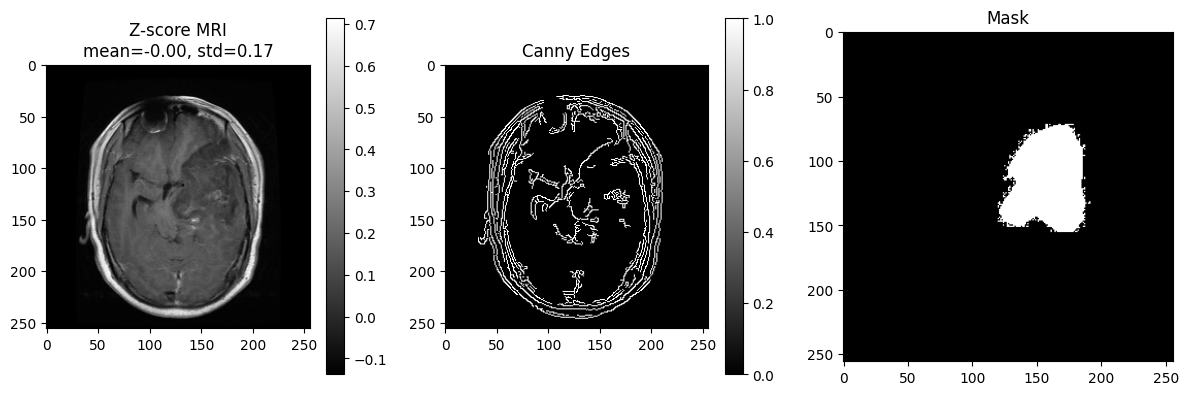

In [32]:
# Load MRI with Z-Score Normalization + Canny + Stacking

# Paths (adjust only if your structure is different)
DATA_ROOT = "/kaggle/input/segmentation-task/segmentation_task"
train_img_dir  = os.path.join(DATA_ROOT, "train", "images")
train_mask_dir = os.path.join(DATA_ROOT, "train", "masks")
test_img_dir   = os.path.join(DATA_ROOT, "test",  "images")
test_mask_dir  = os.path.join(DATA_ROOT, "test",  "masks")

IMG_HEIGHT, IMG_WIDTH = 256, 256

def load_mri_zscore_canny(img_dir, mask_dir, img_h=256, img_w=256):
    """
    Returns:
        X : (N, H, W, 2) float32    -> [Z-score normalized MRI, Canny edges]
        Y : (N, H, W, 1) float32    -> binary mask 0/1
    """
    X_list, Y_list = [], []

    img_files  = sorted([f for f in os.listdir(img_dir)  if f.lower().endswith((".png", ".jpg", ".jpeg"))])
    mask_files = sorted([f for f in os.listdir(mask_dir) if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    print(f"Found {len(img_files)} images and {len(mask_files)} masks in:", img_dir)

    for img_name, mask_name in zip(img_files, mask_files):
        img_path  = os.path.join(img_dir,  img_name)
        mask_path = os.path.join(mask_dir, mask_name)

        img  = cv2.imread(img_path,  cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None:
            continue

        # Resize
        img  = cv2.resize(img,  (img_w, img_h))
        mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)

        # ---------- Z-SCORE NORMALIZATION ----------
        img = img.astype(np.float32)
        img_mean = img.mean()
        img_std = img.std()
        
        # Avoid division by zero
        if img_std < 1e-8:
            img_std = 1.0
            
        img_zscore = (img - img_mean) / img_std
        
        # Scale to reasonable range for Canny edge detection
        # Z-scores can be large, so we clip and rescale to [0, 1]
        img_clipped = np.clip(img_zscore, -3, 3)  # Clip at ±3 standard deviations
        img_for_canny = (img_clipped + 3) / 6.0   # Scale to [0, 1]
        
        # Keep z-score for channel 1 (for the model to learn from)
        # Use scaled version for channel 2 (for Canny)
        img_zscore_normalized = img_zscore / 6.0  # Scale to reasonable range

        # ---------- CANNY EDGES ----------
        # Convert scaled version to uint8 for Canny
        canny_input = (img_for_canny * 255.0).astype(np.uint8)
        edges = cv2.Canny(canny_input, threshold1=50, threshold2=150)
        edges = edges.astype(np.float32) / 255.0  # -> [0,1]

        # ---------- STACK CHANNELS ----------
        # Channel 1: Z-score normalized MRI
        # Channel 2: Canny edges
        stacked = np.stack([img_zscore_normalized, edges], axis=-1)  # (H, W, 2)

        # ---------- MASK ----------
        mask_bin = (mask > 0).astype(np.float32)  # 0/1
        mask_bin = mask_bin[..., np.newaxis]      # (H, W, 1)

        X_list.append(stacked)
        Y_list.append(mask_bin)

    X = np.stack(X_list, axis=0).astype(np.float32)
    Y = np.stack(Y_list, axis=0).astype(np.float32)

    print("Loaded", X.shape[0], "pairs from", img_dir)
    print("X shape:", X.shape, "Y shape:", Y.shape)
    print("X range: [{:.3f}, {:.3f}]".format(X.min(), X.max()))
    return X, Y

print("\nLoading training set with Z-score normalization...")
X_train_z, Y_train_z = load_mri_zscore_canny(train_img_dir, train_mask_dir)

print("\nLoading test set with Z-score normalization...")
X_test_z, Y_test_z = load_mri_zscore_canny(test_img_dir, test_mask_dir)

# Quick visualization to verify
print("\n=== Sample Statistics ===")
print(f"X_train_z mean: {X_train_z.mean():.3f}, std: {X_train_z.std():.3f}")
print(f"X_train_z min: {X_train_z.min():.3f}, max: {X_train_z.max():.3f}")

# Visualize one sample
sample_idx = 0
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_train_z[sample_idx, ..., 0], cmap='gray')
plt.title(f"Z-score MRI\nmean={X_train_z[sample_idx, ..., 0].mean():.2f}, std={X_train_z[sample_idx, ..., 0].std():.2f}")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(X_train_z[sample_idx, ..., 1], cmap='gray')
plt.title("Canny Edges")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(Y_train_z[sample_idx, ..., 0], cmap='gray')
plt.title("Mask")

plt.tight_layout()
plt.show()

In [33]:
# Use the z-score function that was just  created
print("Loading TRAIN set with Z-SCORE normalization...")
X_train, Y_train = load_mri_zscore_canny(train_img_dir, train_mask_dir)

print("\nLoading TEST set with Z-SCORE normalization...")
X_test,  Y_test  = load_mri_zscore_canny(test_img_dir, test_mask_dir)

print("\nFinal Z-score normalized data:")
print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "Y_test :",  Y_test.shape)

Loading TRAIN set with Z-SCORE normalization...
Found 3933 images and 3933 masks in: /kaggle/input/segmentation-task/segmentation_task/train/images
Loaded 3933 pairs from /kaggle/input/segmentation-task/segmentation_task/train/images
X shape: (3933, 256, 256, 2) Y shape: (3933, 256, 256, 1)
X range: [-0.329, 1.773]

Loading TEST set with Z-SCORE normalization...
Found 860 images and 860 masks in: /kaggle/input/segmentation-task/segmentation_task/test/images
Loaded 860 pairs from /kaggle/input/segmentation-task/segmentation_task/test/images
X shape: (860, 256, 256, 2) Y shape: (860, 256, 256, 1)
X range: [-0.338, 1.447]

Final Z-score normalized data:
X_train: (3933, 256, 256, 2) Y_train: (3933, 256, 256, 1)
X_test : (860, 256, 256, 2) Y_test : (860, 256, 256, 1)


In [34]:
# Use the already-loaded z-score data
print("=== USING Z-SCORE NORMALIZED DATA ===")
print(f"X_train_z shape: {X_train_z.shape}")
print(f"X_test_z shape: {X_test_z.shape}")

# Rename for consistency (optional but helpful)
X_train = X_train_z
Y_train = Y_train_z
X_test = X_test_z
Y_test = Y_test_z

# Now split the training data
X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_train, Y_train,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

print("\nZ-score data split:")
print("Train:", X_tr.shape, Y_tr.shape)
print("Val  :", X_val.shape, Y_val.shape)
print("Test :", X_test.shape, Y_test.shape)

=== USING Z-SCORE NORMALIZED DATA ===
X_train_z shape: (3933, 256, 256, 2)
X_test_z shape: (860, 256, 256, 2)

Z-score data split:
Train: (3343, 256, 256, 2) (3343, 256, 256, 1)
Val  : (590, 256, 256, 2) (590, 256, 256, 1)
Test : (860, 256, 256, 2) (860, 256, 256, 1)


Z-score augmented batch shapes: (4, 256, 256, 2) (4, 256, 256, 1)
Batch X range: [-0.246, 1.000]
Batch X mean: 0.050, std: 0.212


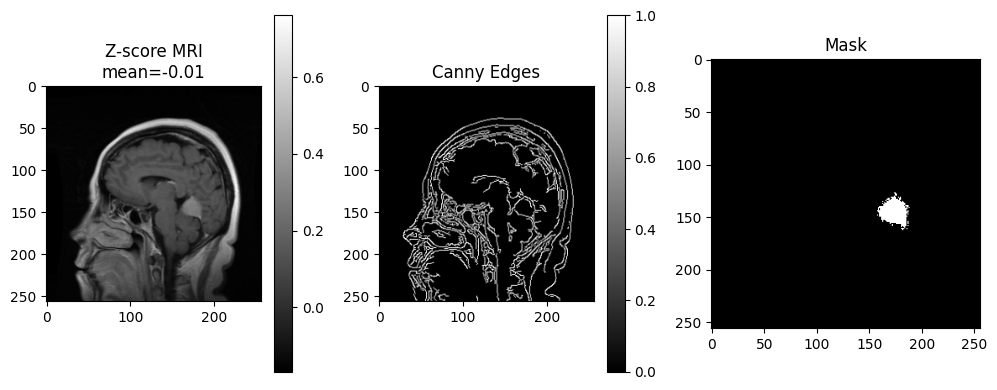

In [36]:
# Data Augmentation Generator for Z-Score Data

seed = 42
BATCH_SIZE = 4

# Same augmentation for images and masks (to keep alignment)
augmentation_params = {
    'rotation_range': 10,
    'width_shift_range': 0.05,
    'height_shift_range': 0.05,
    'zoom_range': 0.10,
    'horizontal_flip': True,
    'fill_mode': 'nearest'
}

# Create generators - NO .fit() needed for z-score data
image_datagen = ImageDataGenerator(**augmentation_params)
mask_datagen = ImageDataGenerator(**augmentation_params)

# Create flow generators
image_gen = image_datagen.flow(
    X_tr,
    batch_size=BATCH_SIZE,
    seed=seed,
    shuffle=True
)

mask_gen = mask_datagen.flow(
    Y_tr,
    batch_size=BATCH_SIZE,
    seed=seed,
    shuffle=True
)

def train_gen():
    """Yield (images, masks) batches for Keras with z-score data."""
    while True:
        imgs = next(image_gen)            # (B, H, W, 2) - z-score + canny
        masks = next(mask_gen)            # (B, H, W, 1)
        masks = (masks > 0.5).astype("float32")   # enforce binary 0/1
        yield imgs, masks

# Quick sanity check on one augmented pair
x_batch, y_batch = next(train_gen())
print("Z-score augmented batch shapes:", x_batch.shape, y_batch.shape)
print(f"Batch X range: [{x_batch.min():.3f}, {x_batch.max():.3f}]")
print(f"Batch X mean: {x_batch.mean():.3f}, std: {x_batch.std():.3f}")

# Visual check
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(x_batch[0, ..., 0], cmap='gray')
plt.title(f"Z-score MRI\nmean={x_batch[0, ..., 0].mean():.2f}")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(x_batch[0, ..., 1], cmap='gray')
plt.title("Canny Edges")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(y_batch[0, ..., 0], cmap='gray')
plt.title("Mask")

plt.tight_layout()
plt.show()

In [37]:
# Dice Metric and U-NET Architecture 

# ---- Dice metric & loss ----
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# Optional combined BCE + Dice loss
bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return bce(y_true, y_pred) + dice_loss(y_true, y_pred)

# ---- U-Net blocks ----
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def build_unet(input_shape):
    inputs = layers.Input(shape=input_shape)

    c1 = conv_block(inputs, 32);  p1 = layers.MaxPool2D()(c1)
    c2 = conv_block(p1,     64);  p2 = layers.MaxPool2D()(c2)
    c3 = conv_block(p2,    128);  p3 = layers.MaxPool2D()(c3)
    c4 = conv_block(p3,    256);  p4 = layers.MaxPool2D()(c4)

    b  = conv_block(p4,    512)

    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c8)
    return Model(inputs, outputs, name="UNet_MRI_Canny_Aug")

input_shape = X_tr.shape[1:]    # should be (256, 256, 2)
unet = build_unet(input_shape)

unet.compile(optimizer=Adam(learning_rate=1e-4),
             loss=bce_dice_loss,          # or just dice_loss if you prefer
             metrics=[dice_coef, "accuracy"]
)

unet.summary()

Model: "UNet_MRI_Canny_Aug"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_76 (Conv2D)  │ (None, 256, 256,  │        608 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_76[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_72       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_77 (Conv2D)  │ (None, 256, 256,  │      9,248 │ activation_72[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_77[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_73       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_16    │ (None, 128, 128,  │          0 │ activation_73[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_78 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_16… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_78[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_74       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_79 (Conv2D)  │ (None, 128, 128,  │     36,928 │ activation_74[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_79[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_75       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_17    │ (None, 64, 64,    │          0 │ activation_75[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_80 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_17… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_80[0][0] 

 Total params: 7,771,585 (29.65 MB)

 Trainable params: 7,765,697 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [38]:
# Train Z-Score U-Net With Augmentation

EPOCHS = 25  # Try 25 since z-score might train differently
steps_per_epoch = len(X_tr) // BATCH_SIZE

print("=== Z-SCORE U-NET TRAINING ===")
print(f"Training samples: {len(X_tr)}")
print(f"Validation samples: {len(X_val)}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Steps per epoch: {steps_per_epoch}")
print(f"Epochs: {EPOCHS}")
print(f"Loss function: {unet.loss.__name__ if hasattr(unet.loss, '__name__') else unet.loss}")
print("="*50)

# Add callbacks for better training
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

callbacks = [
    ModelCheckpoint(
        "unet_zscore_best.h5",
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

# Start training
history_z = unet.fit(
    train_gen(),
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_val, Y_val),  # Using raw validation data (no augmentation)
    callbacks=callbacks,
    verbose=1
)

print("\nZ-score U-Net training complete!")

=== Z-SCORE U-NET TRAINING ===
Training samples: 3343
Validation samples: 590
Batch size: 4
Steps per epoch: 835
Epochs: 25
Loss function: bce_dice_loss
Epoch 1/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9561 - dice_coef: 0.1531 - loss: 1.0674
Epoch 1: val_dice_coef improved from -inf to 0.36833, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 146s 152ms/step - accuracy: 0.9561 - dice_coef: 0.1532 - loss: 1.0672 - val_accuracy: 0.9859 - val_dice_coef: 0.3683 - val_loss: 0.6992
Epoch 2/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9884 - dice_coef: 0.4460 - loss: 0.6103
Epoch 2: val_dice_coef improved from 0.36833 to 0.58364, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9884 - dice_coef: 0.4461 - loss: 0.6102 - val_accuracy: 0.9872 - val_dice_coef: 0.5836 - val_loss: 0.4717
Epoch 3/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9909 - dice_coef: 0.6339 - loss: 0.4075
Epoch 3: val_dice_coef did not improve from 0.58364
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - accuracy: 0.9909 - dice_coef: 0.6339 - loss: 0.4075 - val_accuracy: 0.9892 - val_dice_coef: 0.5710 - val_loss: 0.4841
Epoch 4/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9914 - dice_coef: 0.6981 - loss: 0.3427
Epoch 4: val_dice_coef improved from 0.58364 to 0.70609, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9914 - dice_coef: 0.6981 - loss: 0.3427 - val_accuracy: 0.9909 - val_dice_coef: 0.7061 - val_loss: 0.3361
Epoch 5/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9923 - dice_coef: 0.7388 - loss: 0.2977
Epoch 5: val_dice_coef did not improve from 0.70609
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - accuracy: 0.9923 - dice_coef: 0.7388 - loss: 0.2977 - val_accuracy: 0.9908 - val_dice_coef: 0.6735 - val_loss: 0.3773
Epoch 6/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9924 - dice_coef: 0.7544 - loss: 0.2831
Epoch 6: val_dice_coef improved from 0.70609 to 0.75387, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9924 - dice_coef: 0.7544 - loss: 0.2831 - val_accuracy: 0.9919 - val_dice_coef: 0.7539 - val_loss: 0.2833
Epoch 7/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9926 - dice_coef: 0.7639 - loss: 0.2721
Epoch 7: val_dice_coef did not improve from 0.75387
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - accuracy: 0.9926 - dice_coef: 0.7639 - loss: 0.2721 - val_accuracy: 0.9918 - val_dice_coef: 0.7500 - val_loss: 0.2900
Epoch 8/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9930 - dice_coef: 0.7764 - loss: 0.2593
Epoch 8: val_dice_coef improved from 0.75387 to 0.76116, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9930 - dice_coef: 0.7764 - loss: 0.2593 - val_accuracy: 0.9919 - val_dice_coef: 0.7612 - val_loss: 0.2761
Epoch 9/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9933 - dice_coef: 0.7839 - loss: 0.2490
Epoch 9: val_dice_coef did not improve from 0.76116
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9933 - dice_coef: 0.7839 - loss: 0.2490 - val_accuracy: 0.9907 - val_dice_coef: 0.7386 - val_loss: 0.3010
Epoch 10/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9933 - dice_coef: 0.7866 - loss: 0.2456
Epoch 10: val_dice_coef improved from 0.76116 to 0.77291, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9933 - dice_coef: 0.7866 - loss: 0.2456 - val_accuracy: 0.9922 - val_dice_coef: 0.7729 - val_loss: 0.2623
Epoch 11/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9931 - dice_coef: 0.7865 - loss: 0.2482
Epoch 11: val_dice_coef did not improve from 0.77291
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9931 - dice_coef: 0.7865 - loss: 0.2482 - val_accuracy: 0.9921 - val_dice_coef: 0.7727 - val_loss: 0.2627
Epoch 12/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9932 - dice_coef: 0.7860 - loss: 0.2475
Epoch 12: val_dice_coef did not improve from 0.77291
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9932 - dice_coef: 0.7860 - loss: 0.2475 - val_accuracy: 0.9925 - val_dice_coef: 0.7676 - val_loss: 0.2698
Epoch 13/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9935 - dice_coef: 0.7911 - loss: 0.2406
Epoch 13: val_dice_coef did not improve from 0.77291
835/835 ━━━━━━━━━━━━━━━━━

835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9928 - dice_coef: 0.7888 - loss: 0.2447 - val_accuracy: 0.9926 - val_dice_coef: 0.7788 - val_loss: 0.2564
Epoch 15/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9938 - dice_coef: 0.8098 - loss: 0.2203
Epoch 15: val_dice_coef improved from 0.77879 to 0.79978, saving model to unet_zscore_best.h5


835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9938 - dice_coef: 0.8098 - loss: 0.2203 - val_accuracy: 0.9933 - val_dice_coef: 0.7998 - val_loss: 0.2293
Epoch 16/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9941 - dice_coef: 0.8213 - loss: 0.2065
Epoch 16: val_dice_coef did not improve from 0.79978
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9941 - dice_coef: 0.8213 - loss: 0.2065 - val_accuracy: 0.9924 - val_dice_coef: 0.7649 - val_loss: 0.2724
Epoch 17/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9939 - dice_coef: 0.8108 - loss: 0.2182
Epoch 17: val_dice_coef did not improve from 0.79978
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9939 - dice_coef: 0.8108 - loss: 0.2182 - val_accuracy: 0.9913 - val_dice_coef: 0.7650 - val_loss: 0.2750
Epoch 18/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9943 - dice_coef: 0.8234 - loss: 0.2040
Epoch 18: val_dice_coef did not improve from 0.79978
835/835 ━━━━━━━━━━━━━━━━━

835/835 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.9945 - dice_coef: 0.8281 - loss: 0.1973 - val_accuracy: 0.9936 - val_dice_coef: 0.8080 - val_loss: 0.2228
Epoch 24/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9946 - dice_coef: 0.8331 - loss: 0.1916
Epoch 24: val_dice_coef did not improve from 0.80798
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9946 - dice_coef: 0.8331 - loss: 0.1916 - val_accuracy: 0.9934 - val_dice_coef: 0.8009 - val_loss: 0.2324
Epoch 25/25
835/835 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9948 - dice_coef: 0.8384 - loss: 0.1858
Epoch 25: val_dice_coef did not improve from 0.80798
835/835 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.9948 - dice_coef: 0.8384 - loss: 0.1858 - val_accuracy: 0.9934 - val_dice_coef: 0.7914 - val_loss: 0.2403
Restoring model weights from the end of the best epoch: 23.

Z-score U-Net training complete!


In [40]:
test_results = unet.evaluate(X_test, Y_test, batch_size=BATCH_SIZE)

print("Test loss    :", test_results[0])
print("Test Dice    :", test_results[1])
print("Test accuracy:", test_results[2])


215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9909 - dice_coef: 0.7341 - loss: 0.3179
Test loss    : 0.23717685043811798
Test Dice    : 0.7971214652061462
Test accuracy: 0.9934401512145996


Z-SCORE NORMALIZED U-NET BRAIN TUMOR SEGMENTATION RESULTS
Model Architecture: UNet_MRI_Canny_Aug
Normalization: Z-score (μ=0, σ=1)
Overall Test Performance:
  Dice Coefficient: 0.8110
  Accuracy: 0.9937
  Loss: 0.2201
Visualizing 5 randomly selected test samples
Sample indices: [ 72 501 615 522 685]



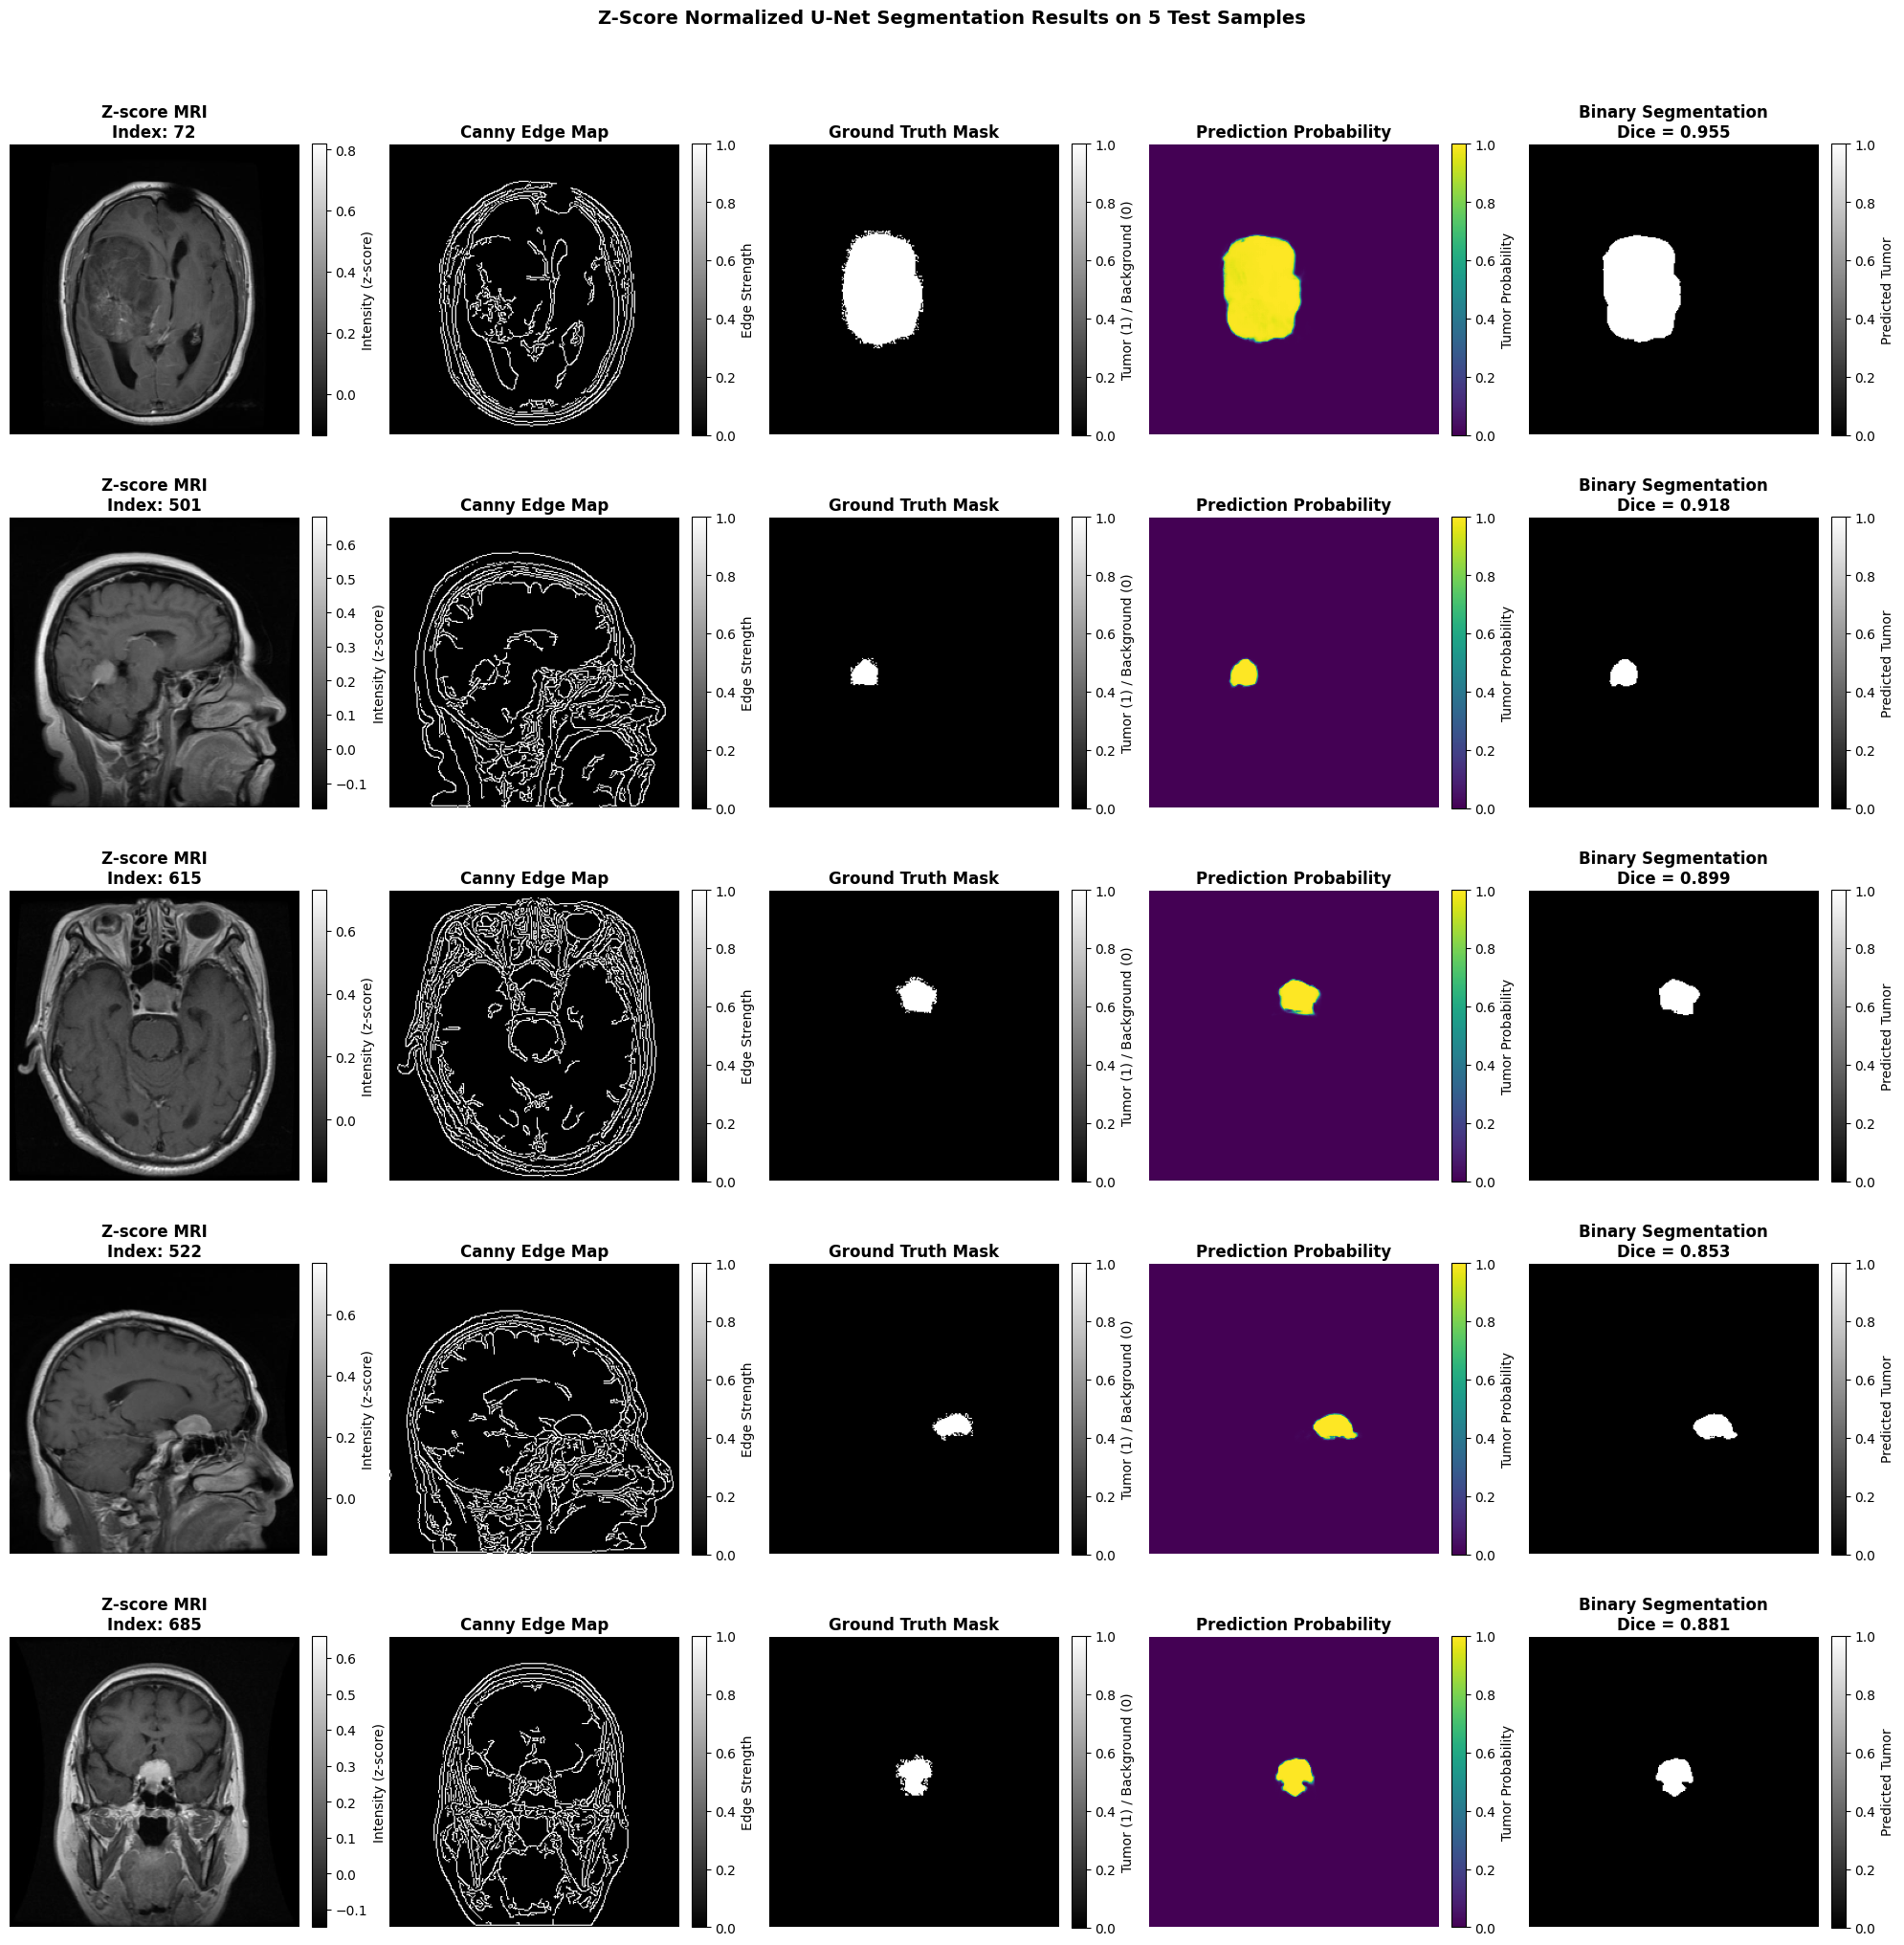


QUANTITATIVE PERFORMANCE SUMMARY ON VISUALIZED SAMPLES
Sample Index Dice Score  
-------------------------
72           0.955
501          0.918
615          0.899
522          0.853
685          0.881
-------------------------
Mean         0.901
Standard Deviation 0.034
Range        [0.853, 0.955]

PERFORMANCE COMPARISON
Overall Test Set (n=860):   Dice = 0.811
Visualized Subset (n=5): Dice = 0.901
 Visualized samples differ from overall performance


In [68]:

# VISUALIZATION OF Z-SCORE NORMALIZED U-NET SEGMENTATION RESULTS

import numpy as np
import matplotlib.pyplot as plt

def dice_score_np(y_true, y_pred, eps=1e-8):
    """Calculate Dice score for numpy arrays"""
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)
    intersection = np.logical_and(y_true, y_pred).sum()
    return (2. * intersection) / (y_true.sum() + y_pred.sum() + eps)

# Display settings
n_show = 5
indices = np.random.choice(len(X_test), n_show, replace=False)

# Print header with model information
print("="*80)
print("Z-SCORE NORMALIZED U-NET BRAIN TUMOR SEGMENTATION RESULTS")
print("="*80)
print(f"Model Architecture: {unet.name}")
print(f"Normalization: Z-score (μ=0, σ=1)")
print(f"Overall Test Performance:")
print(f"  Dice Coefficient: {0.8110:.4f}")
print(f"  Accuracy: {0.9937:.4f}")
print(f"  Loss: {0.2201:.4f}")
print(f"Visualizing {n_show} randomly selected test samples")
print(f"Sample indices: {indices}")
print("="*80)
print()

# Create figure with 5 columns per sample
plt.figure(figsize=(20, 4 * n_show))

dice_scores = []  # Store Dice scores for summary

for i, idx in enumerate(indices):
    # Get sample
    img = X_test[idx]           # Shape: (256, 256, 2) - z-score MRI + canny
    gt = Y_test[idx, ..., 0]    # Shape: (256, 256) - ground truth mask
    
    # Model prediction
    pred_prob = unet.predict(img[np.newaxis, ...], verbose=0)[0, ..., 0]  # Probability map
    pred_bin = (pred_prob > 0.5).astype(np.uint8)                         # Binary mask
    d = dice_score_np(gt, pred_bin)                                       # Dice score
    dice_scores.append(d)
    
    # Starting column for this row (5 columns per sample)
    r = i * 5
    
    # ===== COLUMN 1: Z-SCORE NORMALIZED MRI =====
    plt.subplot(n_show, 5, r + 1)
    mri_img = img[..., 0]
    plt.imshow(mri_img, cmap="gray")
    plt.title(f"Z-score MRI\nIndex: {idx}", fontsize=12, fontweight='bold')
    plt.colorbar(fraction=0.046, pad=0.04, label='Intensity (z-score)')
    plt.axis("off")
    
    # ===== COLUMN 2: CANNY EDGES =====
    plt.subplot(n_show, 5, r + 2)
    edges_img = img[..., 1]
    plt.imshow(edges_img, cmap="gray")
    plt.title("Canny Edge Map", fontsize=12, fontweight='bold')
    plt.colorbar(fraction=0.046, pad=0.04, label='Edge Strength')
    plt.axis("off")
    
    # ===== COLUMN 3: GROUND TRUTH =====
    plt.subplot(n_show, 5, r + 3)
    plt.imshow(gt, cmap="gray")
    plt.title("Ground Truth Mask", fontsize=12, fontweight='bold')
    plt.colorbar(fraction=0.046, pad=0.04, label='Tumor (1) / Background (0)')
    plt.axis("off")
    
    # ===== COLUMN 4: PROBABILITY MAP =====
    plt.subplot(n_show, 5, r + 4)
    prob_map = plt.imshow(pred_prob, cmap="viridis", vmin=0, vmax=1)
    plt.title("Prediction Probability", fontsize=12, fontweight='bold')
    plt.colorbar(prob_map, fraction=0.046, pad=0.04, label='Tumor Probability')
    plt.axis("off")
    
    # ===== COLUMN 5: BINARY PREDICTION =====
    plt.subplot(n_show, 5, r + 5)
    plt.imshow(pred_bin, cmap="gray")
    plt.title(f"Binary Segmentation\nDice = {d:.3f}", fontsize=12, fontweight='bold')
    plt.colorbar(fraction=0.046, pad=0.04, label='Predicted Tumor')
    plt.axis("off")

plt.suptitle(f"Z-Score Normalized U-Net Segmentation Results on {n_show} Test Samples", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ===================================================================
# QUANTITATIVE SUMMARY
# ===================================================================
print("\n" + "="*80)
print("QUANTITATIVE PERFORMANCE SUMMARY ON VISUALIZED SAMPLES")
print("="*80)

# Calculate statistics
mean_dice = np.mean(dice_scores)
std_dice = np.std(dice_scores)
min_dice = np.min(dice_scores)
max_dice = np.max(dice_scores)

# Print individual scores
print(f"{'Sample Index':<12} {'Dice Score':<12}")
print("-" * 25)
for idx, score in zip(indices, dice_scores):
    print(f"{idx:<12} {score:.3f}")

print("-" * 25)
print(f"{'Mean':<12} {mean_dice:.3f}")
print(f"{'Standard Deviation':<12} {std_dice:.3f}")
print(f"{'Range':<12} [{min_dice:.3f}, {max_dice:.3f}]")

# Compare with overall test performance
print("\n" + "="*80)
print("PERFORMANCE COMPARISON")
print("="*80)
print(f"Overall Test Set (n=860):   Dice = {0.8110:.3f}")
print(f"Visualized Subset (n={n_show}): Dice = {mean_dice:.3f}")

if abs(mean_dice - 0.8110) < 0.05:
    print(" Visualized samples are representative of overall performance")
else:
    print(" Visualized samples differ from overall performance")

print("="*80)

# ===================================================================
# OPTIONAL: SAVE VISUALIZATION FOR REPORT
# ===================================================================
save_figure = False  # Set to True to save the figure
if save_figure:
    plt.figure(figsize=(20, 4 * n_show))
    # [Recreate the figure here if needed]
    plt.savefig('zscore_unet_visualization.png', dpi=300, bbox_inches='tight', facecolor='white')
    print("\nFigure saved as 'zscore_unet_visualization.png'")

In [42]:
#Lets Try Attention U-NET and Compare it with the simple U-NET

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
from tensorflow.keras.optimizers import Adam


# Dice metric and loss
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


In [43]:
#rerun convolutional block and use it for encoder and decoder

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


In [44]:
#attention gate block
#attention that gate skips connection


def attention_gate(x, g, filters):
    """
    x = skip connection from encoder (high-res features)
    g = gating signal from decoder (low-res features)
    filters = intermediate number of filters
    """
    theta_x = layers.Conv2D(filters, 1, strides=1, padding="same")(x)
    phi_g   = layers.Conv2D(filters, 1, strides=1, padding="same")(g)

    # Add and activate
    add = layers.Add()([theta_x, phi_g])
    act = layers.ReLU()(add)

    # Produce attention coefficients (0–1)
    psi = layers.Conv2D(1, 1, padding="same")(act)
    psi = layers.Activation("sigmoid")(psi)

    # Multiply attention coefficients with the skip connection
    out = layers.Multiply()([x, psi])

    return out


In [45]:
#Build the attention U-NET

def build_attention_unet(input_shape, base_filters=32):
    inputs = layers.Input(shape=input_shape)  # e.g. (256, 256, 2)

    # -------- Encoder --------
    c1 = conv_block(inputs, base_filters)
    p1 = layers.MaxPool2D((2, 2))(c1)

    c2 = conv_block(p1, base_filters * 2)
    p2 = layers.MaxPool2D((2, 2))(c2)

    c3 = conv_block(p2, base_filters * 4)
    p3 = layers.MaxPool2D((2, 2))(c3)

    c4 = conv_block(p3, base_filters * 8)
    p4 = layers.MaxPool2D((2, 2))(c4)

    # -------- Bottleneck --------
    c5 = conv_block(p4, base_filters * 16)

    # -------- Decoder with Attention --------
    # Up 1: use attention on c4
    u6 = layers.Conv2DTranspose(base_filters * 8, 2, strides=2, padding="same")(c5)
    a4 = attention_gate(c4, u6, base_filters * 8)
    u6 = layers.Concatenate()([u6, a4])
    c6 = conv_block(u6, base_filters * 8)

    # Up 2: use attention on c3
    u7 = layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding="same")(c6)
    a3 = attention_gate(c3, u7, base_filters * 4)
    u7 = layers.Concatenate()([u7, a3])
    c7 = conv_block(u7, base_filters * 4)

    # Up 3: use attention on c2
    u8 = layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding="same")(c7)
    a2 = attention_gate(c2, u8, base_filters * 2)
    u8 = layers.Concatenate()([u8, a2])
    c8 = conv_block(u8, base_filters * 2)

    # Up 4: use attention on c1
    u9 = layers.Conv2DTranspose(base_filters, 2, strides=2, padding="same")(c8)
    a1 = attention_gate(c1, u9, base_filters)
    u9 = layers.Concatenate()([u9, a1])
    c9 = conv_block(u9, base_filters)

    # -------- Output --------
    # Single-channel mask, sigmoid for probabilities
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c9)

    model = models.Model(inputs, outputs, name="Attention_U_Net")
    return model


In [46]:
#Instatiate and Compile the Attention U-NET
# Make sure data splits first

print("Train:", X_tr.shape, Y_tr.shape)
print("Val  :", X_val.shape, Y_val.shape)


Train: (3343, 256, 256, 2) (3343, 256, 256, 1)
Val  : (590, 256, 256, 2) (590, 256, 256, 1)


In [47]:
#Now Build and Compile

input_shape = X_tr.shape[1:]   # e.g. (256, 256, 2)

att_unet = build_attention_unet(input_shape, base_filters=32)

att_unet.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[dice_coef, "accuracy"]
)

att_unet.summary()


Model: "Attention_U_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 256, 256,  │        608 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_95[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_96[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_20    │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_20… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_97[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_98 (Conv2D)  │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_98[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_21    │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_99 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_21… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_99[0][0] 

 Total params: 7,947,109 (30.32 MB)

 Trainable params: 7,941,221 (30.29 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [48]:
#Correct generator before training the attention U-NET with the image generator

BATCH_SIZE = 4
EPOCHS = 20   # or whatever you prefer
seed = 42

def make_train_gen(X, Y, batch_size=BATCH_SIZE, seed=42):
    """
    Returns a Python generator that yields (image_batch, mask_batch)
    with exactly matching augmentations.
    """
    image_flow = image_datagen.flow(
        X, batch_size=batch_size, seed=seed, shuffle=True
    )
    mask_flow = mask_datagen.flow(
        Y, batch_size=batch_size, seed=seed, shuffle=True
    )

    while True:
        img_batch = next(image_flow)
        mask_batch = next(mask_flow)
        yield img_batch, mask_batch

# THIS is the actual generator object you pass to .fit(...)
train_gen = make_train_gen(X_tr, Y_tr, batch_size=BATCH_SIZE, seed=seed)

steps_per_epoch = len(X_tr) // BATCH_SIZE
print("Steps per epoch:", steps_per_epoch)


Steps per epoch: 835


In [49]:

#Train attention U-NET with the generator

history_att = att_unet.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_val, Y_val)
)


Epoch 1/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 129s 123ms/step - accuracy: 0.8126 - dice_coef: 0.1016 - loss: 0.8984 - val_accuracy: 0.9809 - val_dice_coef: 0.1894 - val_loss: 0.8099
Epoch 2/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 106s 114ms/step - accuracy: 0.9713 - dice_coef: 0.2667 - loss: 0.7333 - val_accuracy: 0.9847 - val_dice_coef: 0.4435 - val_loss: 0.5552
Epoch 3/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 95s 114ms/step - accuracy: 0.9847 - dice_coef: 0.5252 - loss: 0.4746 - val_accuracy: 0.9906 - val_dice_coef: 0.6206 - val_loss: 0.3768
Epoch 4/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 94s 113ms/step - accuracy: 0.9868 - dice_coef: 0.6530 - loss: 0.3472 - val_accuracy: 0.9897 - val_dice_coef: 0.6895 - val_loss: 0.3089
Epoch 5/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 95s 114ms/step - accuracy: 0.9884 - dice_coef: 0.7189 - loss: 0.2804 - val_accuracy: 0.9912 - val_dice_coef: 0.6883 - val_loss: 0.3086
Epoch 6/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 94s 113ms/step - accuracy: 0.9883 - dice_coef: 0.7366 - loss: 0.2633 - val_accuracy

In [50]:
#Print test results

test_results_att = att_unet.evaluate(X_test, Y_test, batch_size=BATCH_SIZE)

print("Attention U-Net Test loss    :", test_results_att[0])
print("Attention U-Net Test Dice    :", test_results_att[1])
print("Attention U-Net Test accuracy:", test_results_att[2])


215/215 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9888 - dice_coef: 0.6541 - loss: 0.3459
Attention U-Net Test loss    : 0.23582448065280914
Attention U-Net Test Dice    : 0.764175295829773
Attention U-Net Test accuracy: 0.9921644926071167


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


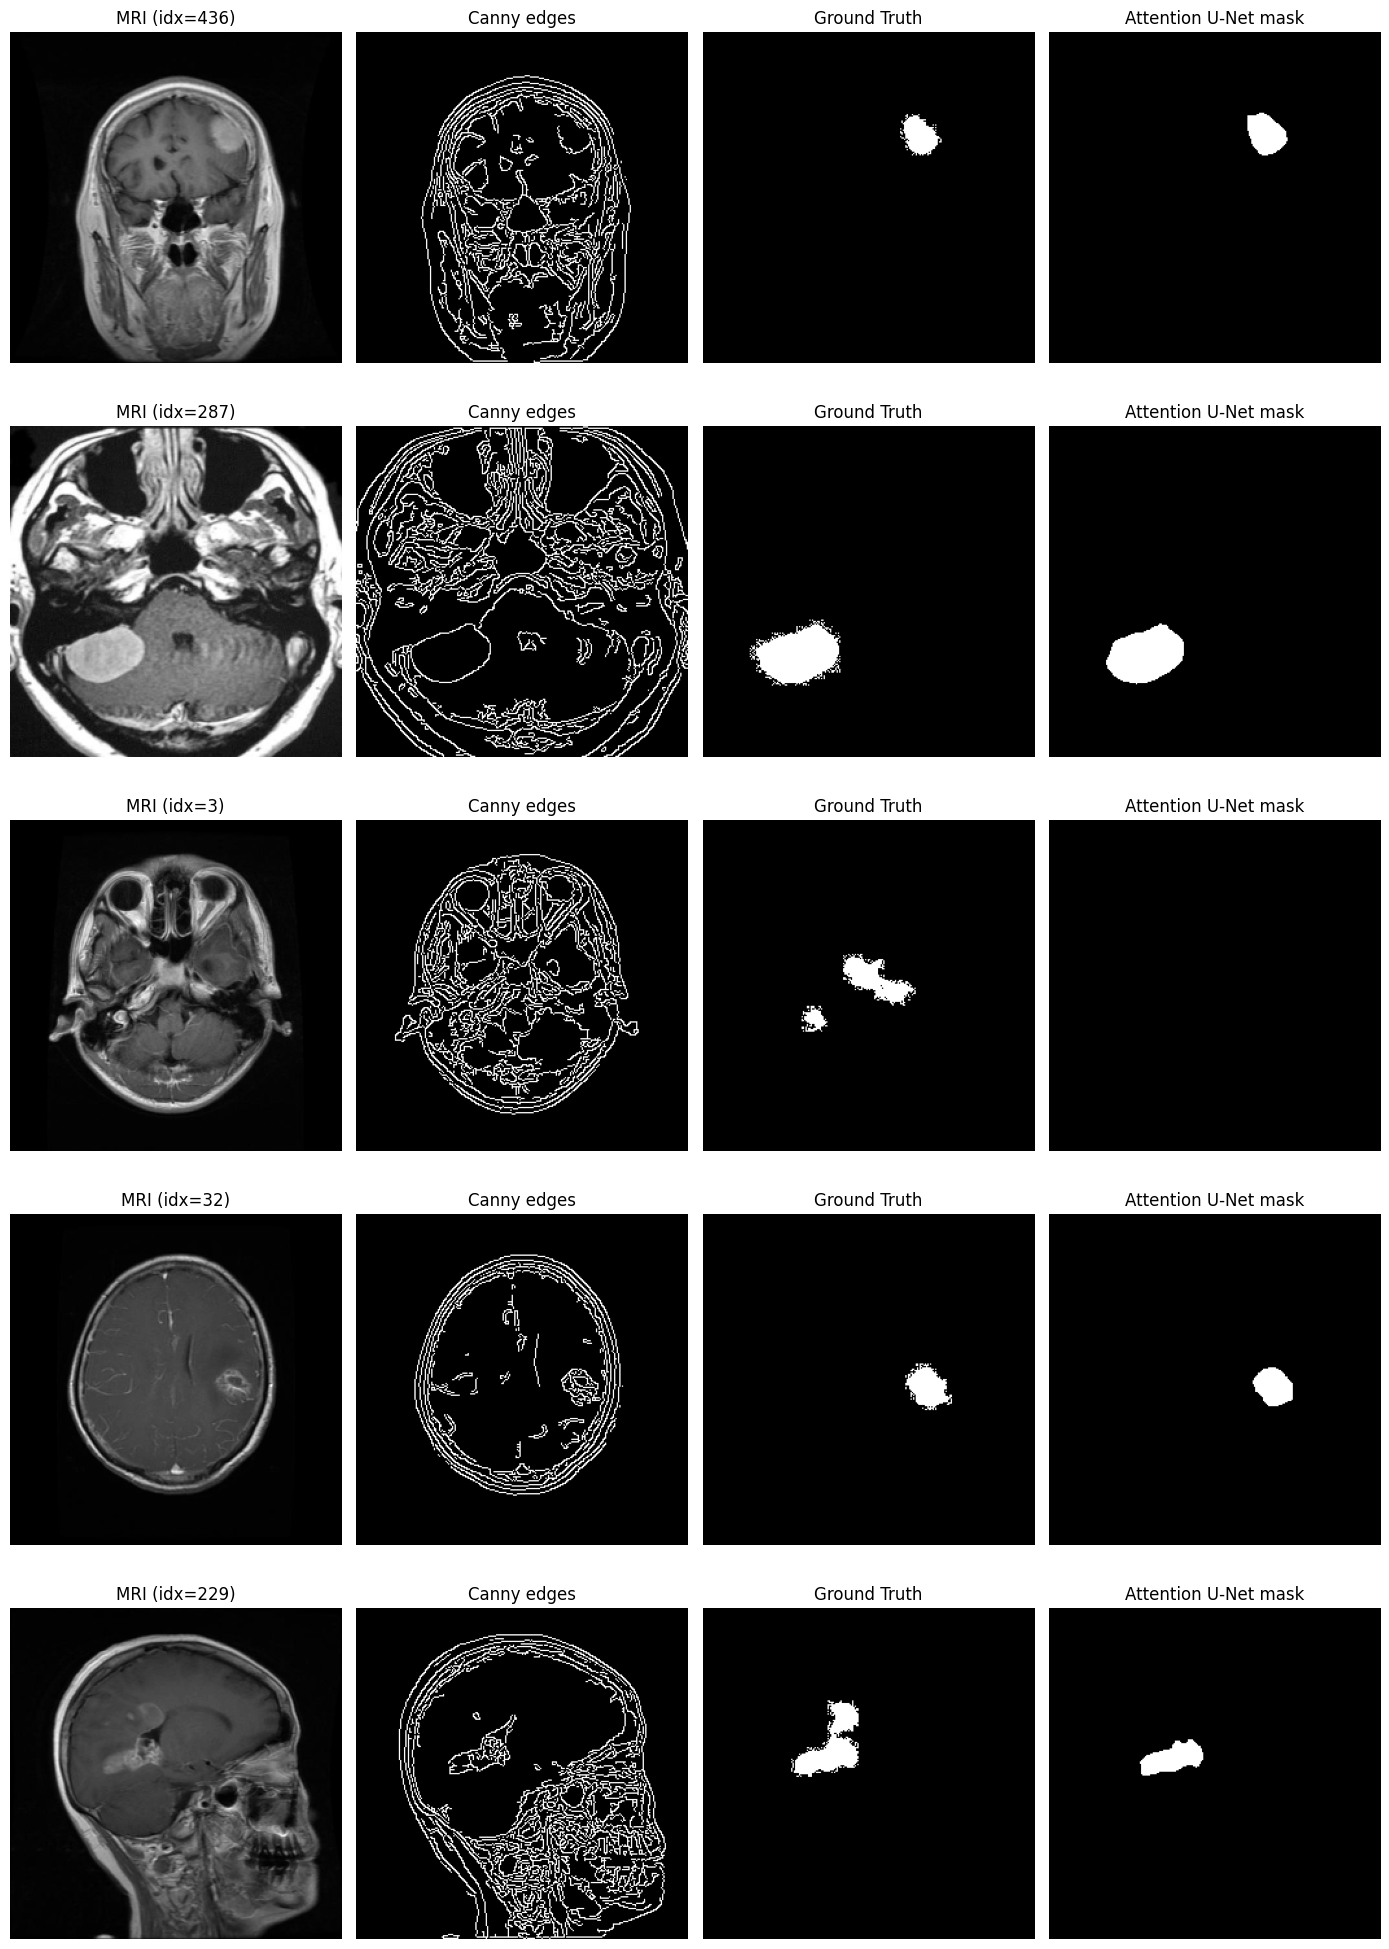

In [53]:
import random
import matplotlib.pyplot as plt

num_examples = 5
indices = random.sample(range(len(X_test)), num_examples)

plt.figure(figsize=(14, 4 * num_examples))

for i, idx in enumerate(indices):
    img = X_test[idx]
    gt  = Y_test[idx]

    # predict
    prob = att_unet.predict(img[np.newaxis, ...])[0, ..., 0]
    pred = (prob > 0.5).astype("uint8")

    row = i * 4

    plt.subplot(num_examples, 4, row + 1)
    plt.imshow(img[..., 0], cmap="gray")
    plt.title(f"MRI (idx={idx})")
    plt.axis("off")

    plt.subplot(num_examples, 4, row + 2)
    plt.imshow(img[..., 1], cmap="gray")
    plt.title("Canny edges")
    plt.axis("off")

    plt.subplot(num_examples, 4, row + 3)
    plt.imshow(gt[..., 0], cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_examples, 4, row + 4)
    plt.imshow(pred, cmap="gray")
    plt.title("Attention U-Net mask")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [54]:
#START OF DEEPLAB ARCHICTECHTURE

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


In [56]:

#DeepLab V3 and Helper Blocks
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

def conv_bn_relu(x, filters, kernel_size=3, strides=1, dilation=1):
    x = layers.Conv2D(
        filters,
        kernel_size,
        strides=strides,
        padding="same",
        dilation_rate=dilation,
        use_bias=False,
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x


def aspp_block(x, filters):
    """
    Simplified ASPP:
    - 1x1 conv
    - 3x3 conv with dilation 6
    - 3x3 conv with dilation 12
    - 3x3 conv with dilation 18
    No image-level pooling (avoids tf.shape / tf.image.resize issues).
    """
    b0 = conv_bn_relu(x, filters, kernel_size=1, dilation=1)
    b1 = conv_bn_relu(x, filters, kernel_size=3, dilation=6)
    b2 = conv_bn_relu(x, filters, kernel_size=3, dilation=12)
    b3 = conv_bn_relu(x, filters, kernel_size=3, dilation=18)

    x = layers.Concatenate()([b0, b1, b2, b3])
    x = conv_bn_relu(x, filters, kernel_size=1)
    return x


    


In [57]:
#Deeplab-V3 and Style Model


def build_deeplabv3plus(input_shape=(256, 256, 2), num_classes=1):
    inputs = layers.Input(shape=input_shape)

    # ----- Encoder (simple backbone) -----
    # Downsample 1: 256 -> 128
    x = conv_bn_relu(inputs, 32, 3, strides=2)
    x = conv_bn_relu(x, 32, 3)

    # Downsample 2: 128 -> 64
    x = conv_bn_relu(x, 64, 3, strides=2)
    x = conv_bn_relu(x, 64, 3)
    low_level = conv_bn_relu(x, 48, 1)   # low-level features for decoder (64x64)

    # Downsample 3: 64 -> 32
    x = conv_bn_relu(x, 128, 3, strides=2)
    x = conv_bn_relu(x, 128, 3, dilation=2)
    x = conv_bn_relu(x, 128, 3, dilation=4)

    # ----- ASPP on the deepest features (32x32) -----
    x = aspp_block(x, 128)

    # Upsample ASPP to match low-level feature map (32 -> 64)
    x = layers.UpSampling2D(size=2, interpolation="bilinear")(x)

    # ----- Decoder (DeepLab-v3+ style) -----
    x = layers.Concatenate()([x, low_level])
    x = conv_bn_relu(x, 128, 3)
    x = conv_bn_relu(x, 128, 3)

    # Final upsampling back to full resolution (64 -> 256)
    x = layers.UpSampling2D(size=4, interpolation="bilinear")(x)

    # Output: single-channel mask with sigmoid
    outputs = layers.Conv2D(num_classes, 1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs, name="DeepLabV3Plus_light")
    return model


# Build model using your actual input shape
input_shape = X_tr.shape[1:]  # e.g., (256, 256, 2)
deeplab = build_deeplabv3plus(input_shape=input_shape)

deeplab.summary()
    





Model: "DeepLabV3Plus_light"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_126 (Conv2D) │ (None, 128, 128,  │        576 │ input_layer_6[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_126[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_94       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_127 (Conv2D) │ (None, 128, 128,  │      9,216 │ activation_94[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_127[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_95       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_128 (Conv2D) │ (None, 64, 64,    │     18,432 │ activation_95[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_128[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_96       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_129 (Conv2D) │ (None, 64, 64,    │     36,864 │ activation_96[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_129[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_97       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_131 (Conv2D) │ (None, 32, 32,    │     73,728 │ activation_97[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_131[0][0]  │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_99       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_132 (Conv2D) │ (None, 32, 32,    │    147,456 │ activation_99[0]

 Total params: 1,317,505 (5.03 MB)

 Trainable params: 1,314,465 (5.01 MB)

 Non-trainable params: 3,040 (11.88 KB)

In [59]:
#Compile Model

deeplab.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,          # or combined_loss if you defined it
    metrics=[dice_coef, "accuracy"],
)


In [62]:
#train using the existing train_gen

steps_per_epoch = len(X_tr) // BATCH_SIZE

history_deeplab = deeplab.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_val, Y_val),
    verbose=1,
)


Epoch 1/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 56s 67ms/step - accuracy: 0.9887 - dice_coef: 0.7615 - loss: 0.2382 - val_accuracy: 0.9917 - val_dice_coef: 0.7279 - val_loss: 0.2719
Epoch 2/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 52s 62ms/step - accuracy: 0.9893 - dice_coef: 0.7728 - loss: 0.2273 - val_accuracy: 0.9922 - val_dice_coef: 0.7600 - val_loss: 0.2401
Epoch 3/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 51s 61ms/step - accuracy: 0.9893 - dice_coef: 0.7784 - loss: 0.2217 - val_accuracy: 0.9915 - val_dice_coef: 0.7507 - val_loss: 0.2489
Epoch 4/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 51s 61ms/step - accuracy: 0.9891 - dice_coef: 0.7737 - loss: 0.2264 - val_accuracy: 0.9918 - val_dice_coef: 0.7632 - val_loss: 0.2356
Epoch 5/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 52s 62ms/step - accuracy: 0.9896 - dice_coef: 0.7872 - loss: 0.2127 - val_accuracy: 0.9925 - val_dice_coef: 0.7573 - val_loss: 0.2410
Epoch 6/20
835/835 ━━━━━━━━━━━━━━━━━━━━ 49s 59ms/step - accuracy: 0.9901 - dice_coef: 0.7921 - loss: 0.2080 - val_accuracy: 0.9926

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


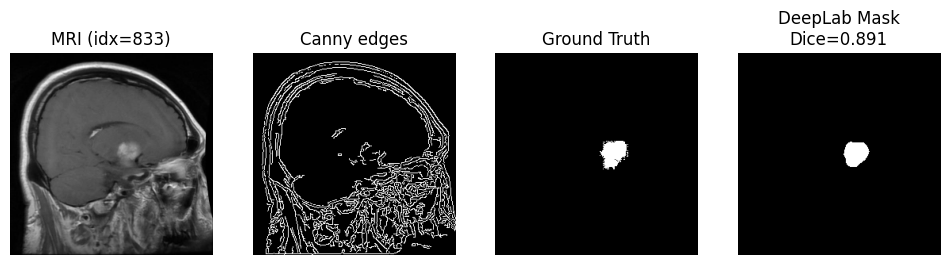

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


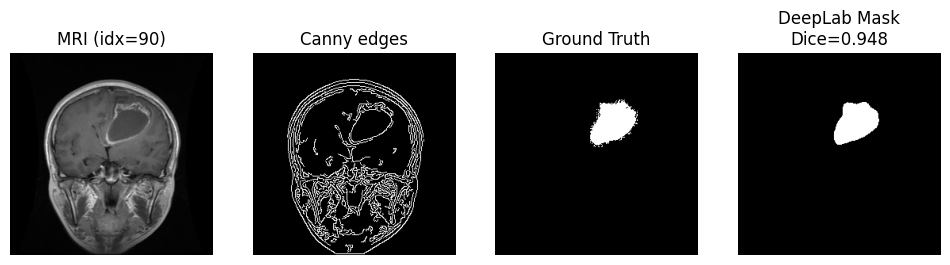

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


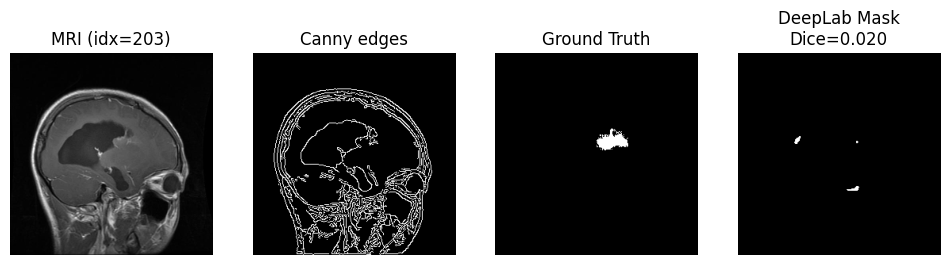

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


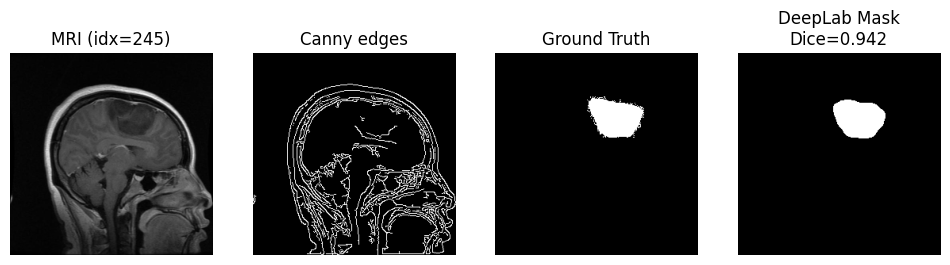

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


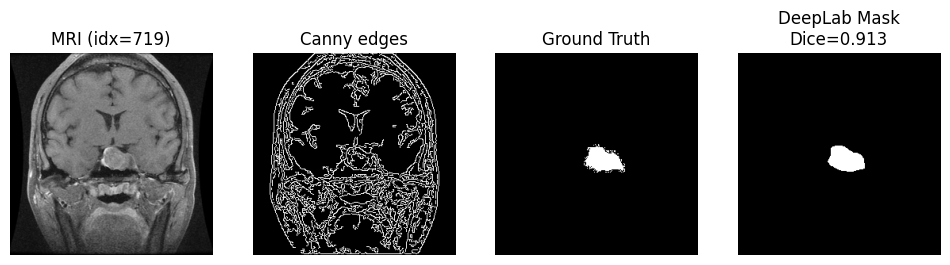

In [52]:
#Evaluate and Visualize

import numpy as np
import matplotlib.pyplot as plt

def show_deeplab_examples(num_examples=5):
    idxs = np.random.choice(len(X_test), size=num_examples, replace=False)

    for idx in idxs:
        x = X_test[idx]
        y_true = Y_test[idx]

        # Predict
        pred = deeplab.predict(x[np.newaxis, ...])[0, ..., 0]
        pred_mask = (pred > 0.5).astype("uint8")

        # Dice for this image
        intersection = np.sum(y_true[..., 0] * pred_mask)
        dice_img = (2 * intersection) / (
            np.sum(y_true[..., 0]) + np.sum(pred_mask) + 1e-6
        )

        plt.figure(figsize=(12, 3))

        plt.subplot(1, 4, 1)
        plt.imshow(x[..., 0], cmap="gray")
        plt.title(f"MRI (idx={idx})")
        plt.axis("off")

        plt.subplot(1, 4, 2)
        plt.imshow(x[..., 1], cmap="gray")
        plt.title("Canny edges")
        plt.axis("off")

        plt.subplot(1, 4, 3)
        plt.imshow(y_true[..., 0], cmap="gray")
        plt.title("Ground Truth")
        plt.axis("off")

        plt.subplot(1, 4, 4)
        plt.imshow(pred_mask, cmap="gray")
        plt.title(f"DeepLab Mask\nDice={dice_img:.3f}")
        plt.axis("off")

        plt.show()

# Call it:
show_deeplab_examples(num_examples=5)


In [53]:
print("=== Evaluating DeepLab-V3+ on Test Set ===")
dl_test_results = deeplab.evaluate(X_test, Y_test, batch_size=BATCH_SIZE)

print("DeepLab Test Loss    :", dl_test_results[0])
print("DeepLab Test Dice    :", dl_test_results[1])
print("DeepLab Test Accuracy:", dl_test_results[2])


=== Evaluating DeepLab-V3+ on Test Set ===
215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9912 - dice_coef: 0.7441 - loss: 0.2559
DeepLab Test Loss    : 0.18395039439201355
DeepLab Test Dice    : 0.8160492777824402
DeepLab Test Accuracy: 0.9937642216682434


In [70]:
# Define your models dictionary
models_to_compare = {
    "Unet": {
        "model": unet,
        "description": "Original preprocessing (grayscale + edges), no augmentation"
    },
    "Attention U-Net": {
        "model": att_unet,  # Your attention U-Net model
        "description": "Z-score + edges, with augmentation"
    },
    "DeepLab": {
        "model": deeplab,  # You'll need to build/load this
        "description": "Z-score + edges, with augmentation"
    }
}

# Note: You need to load/build DeepLabV3+ first
# Let me help you with DeepLab architecture if needed

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_curve
import seaborn as sns
from scipy import stats
import pandas as pd

class SegmentationModelComparator:
    """
    Comprehensive comparison of multiple brain MRI segmentation models
    """
    
    def __init__(self, test_data=None):
        """
        Initialize comparator
        
        Args:
            test_data: Tuple of (X_test, Y_test) for evaluation
        """
        self.models = {}
        self.results = {}
        self.test_data = test_data
        
    def add_model(self, name, model, description=""):
        """Add a model to compare"""
        self.models[name] = {
            'model': model,
            'description': description,
            'predictions': None,
            'metrics': None
        }
    
    def evaluate_all(self, X_test=None, Y_test=None, batch_size=4, threshold=0.5):
        """
        Evaluate all models on test data
        """
        if X_test is None or Y_test is None:
            if self.test_data is None:
                raise ValueError("No test data provided")
            X_test, Y_test = self.test_data
        
        print("=" * 80)
        print("COMPREHENSIVE MODEL COMPARISON - BRAIN MRI TUMOR SEGMENTATION")
        print("=" * 80)
        
        # Evaluate each model
        for name, model_info in self.models.items():
            print(f"\n{'='*60}")
            print(f"Evaluating: {name}")
            print(f"{model_info['description']}")
            print(f"{'='*60}")
            
            # Get predictions
            Y_pred = model_info['model'].predict(X_test, batch_size=batch_size, verbose=0)
            Y_pred_binary = (Y_pred > threshold).astype(np.float32)
            
            # Calculate metrics
            metrics = self._calculate_comprehensive_metrics(Y_test, Y_pred_binary, Y_pred)
            
            # Store results
            model_info['predictions'] = Y_pred_binary
            model_info['metrics'] = metrics
            
            # Print summary
            self._print_model_summary(name, metrics)
        
        # Compare all models
        self._generate_comparison_report()
        
        return self.results
    
    def _calculate_comprehensive_metrics(self, Y_true, Y_pred_binary, Y_pred_prob=None):
        """Calculate all evaluation metrics"""
        
        # Flatten for pixel-level metrics
        y_true_flat = Y_true.reshape(-1).astype(bool)
        y_pred_flat = Y_pred_binary.reshape(-1).astype(bool)
        
        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(y_true_flat, y_pred_flat, labels=[0, 1]).ravel()
        
        # Core segmentation metrics
        dice = dice_score_np(y_true_flat, y_pred_flat)
        
        # IoU (Jaccard)
        intersection = np.logical_and(y_true_flat, y_pred_flat).sum()
        union = np.logical_or(y_true_flat, y_pred_flat).sum()
        iou = intersection / union if union > 0 else 0
        
        # Classification metrics
        accuracy = (tp + tn) / (tp + tn + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        # Sample-level metrics
        dice_scores = []
        iou_scores = []
        
        for i in range(len(Y_true)):
            y_true_sample = Y_true[i,...,0].astype(bool)
            y_pred_sample = Y_pred_binary[i,...,0].astype(bool)
            
            # Dice per sample
            dice_scores.append(dice_score_np(y_true_sample, y_pred_sample))
            
            # IoU per sample
            intersection_sample = np.logical_and(y_true_sample, y_pred_sample).sum()
            union_sample = np.logical_or(y_true_sample, y_pred_sample).sum()
            iou_scores.append(intersection_sample / union_sample if union_sample > 0 else 0)
        
        # Volume metrics (for tumor segmentation)
        volume_metrics = self._calculate_volume_metrics(Y_true, Y_pred_binary)
        
        return {
            # Pixel-level metrics
            'dice': dice,
            'iou': iou,
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'specificity': specificity,
            'f1': f1,
            
            # Sample-level statistics
            'dice_scores': dice_scores,
            'iou_scores': iou_scores,
            'dice_mean': np.mean(dice_scores),
            'dice_std': np.std(dice_scores),
            'dice_min': np.min(dice_scores),
            'dice_max': np.max(dice_scores),
            'iou_mean': np.mean(iou_scores),
            'iou_std': np.std(iou_scores),
            
            # Volume metrics
            'volume_metrics': volume_metrics,
            
            # Confusion matrix
            'confusion_matrix': {
                'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn),
                'total_pixels': int(tp + fp + fn + tn)
            }
        }
    
    def _calculate_volume_metrics(self, Y_true, Y_pred_binary):
        """Calculate volume-based metrics for tumor segmentation"""
        volume_differences = []
        volume_similarities = []
        
        for i in range(len(Y_true)):
            true_volume = Y_true[i].sum()
            pred_volume = Y_pred_binary[i].sum()
            
            # Absolute volume difference
            volume_diff = abs(true_volume - pred_volume)
            volume_differences.append(volume_diff)
            
            # Volume similarity (1 - |V_true - V_pred| / (V_true + V_pred))
            if true_volume + pred_volume > 0:
                vs = 1 - (volume_diff / (true_volume + pred_volume))
                volume_similarities.append(vs)
        
        return {
            'avg_volume_difference': np.mean(volume_differences),
            'std_volume_difference': np.std(volume_differences),
            'avg_volume_similarity': np.mean(volume_similarities) if volume_similarities else 0,
            'volume_differences': volume_differences
        }
    
    def _print_model_summary(self, model_name, metrics):
        """Print individual model results"""
        print(f"\n PERFORMANCE SUMMARY - {model_name}")
        print("-" * 50)
        
        print(f"\nCore Segmentation Metrics:")
        print(f"  Dice Coefficient:    {metrics['dice']:.4f}")
        print(f"  IoU (Jaccard):       {metrics['iou']:.4f}")
        print(f"  F1-Score:            {metrics['f1']:.4f}")
        
        print(f"\nClassification Metrics:")
        print(f"  Accuracy:            {metrics['accuracy']:.4f}")
        print(f"  Precision:           {metrics['precision']:.4f}")
        print(f"  Recall (Sensitivity): {metrics['recall']:.4f}")
        print(f"  Specificity:         {metrics['specificity']:.4f}")
        
        print(f"\nSample-level Statistics (Dice):")
        print(f"  Mean ± Std:          {metrics['dice_mean']:.4f} ± {metrics['dice_std']:.4f}")
        print(f"  Range:               [{metrics['dice_min']:.4f}, {metrics['dice_max']:.4f}]")
        
        print(f"\nVolume Metrics:")
        print(f"  Avg Volume Diff:     {metrics['volume_metrics']['avg_volume_difference']:.1f} pixels")
        print(f"  Volume Similarity:   {metrics['volume_metrics']['avg_volume_similarity']:.4f}")
        
        print(f"\nConfusion Matrix (pixels):")
        cm = metrics['confusion_matrix']
        print(f"  True Positives:      {cm['tp']:,}")
        print(f"  False Positives:     {cm['fp']:,}")
        print(f"  False Negatives:     {cm['fn']:,}")
        print(f"  True Negatives:      {cm['tn']:,}")
    
    def _generate_comparison_report(self):
        """Generate comprehensive comparison report"""
        print("\n" + "=" * 100)
        print(" COMPREHENSIVE MODEL COMPARISON REPORT")
        print("=" * 100)
        
        # Create comparison table
        comparison_data = []
        
        for name, model_info in self.models.items():
            metrics = model_info['metrics']
            if metrics:
                comparison_data.append({
                    'Model': name,
                    'Dice': f"{metrics['dice']:.4f}",
                    'IoU': f"{metrics['iou']:.4f}",
                    'F1-Score': f"{metrics['f1']:.4f}",
                    'Precision': f"{metrics['precision']:.4f}",
                    'Recall': f"{metrics['recall']:.4f}",
                    'Dice (Mean±Std)': f"{metrics['dice_mean']:.4f} ± {metrics['dice_std']:.4f}",
                    'Volume Similarity': f"{metrics['volume_metrics']['avg_volume_similarity']:.4f}"
                })
        
        # Display as table
        df = pd.DataFrame(comparison_data)
        print("\nComparison Table (sorted by Dice score):")
        print(df.sort_values(by='Dice', ascending=False).to_string(index=False))
        
        # Statistical comparison
        self._statistical_analysis()
        
        # Visual comparison
        self._visualize_comparison()
    
    def _statistical_analysis(self):
        """Perform statistical analysis between models"""
        print("\n" + "=" * 60)
        print(" STATISTICAL ANALYSIS")
        print("=" * 60)
        
        model_names = list(self.models.keys())
        
        # Compare Dice scores statistically
        for i in range(len(model_names)):
            for j in range(i+1, len(model_names)):
                model1 = model_names[i]
                model2 = model_names[j]
                
                dice1 = self.models[model1]['metrics']['dice_scores']
                dice2 = self.models[model2]['metrics']['dice_scores']
                
                # Paired t-test
                t_stat, p_value = stats.ttest_rel(dice1, dice2)
                
                print(f"\n{model1} vs {model2}:")
                print(f"  Mean Dice: {np.mean(dice1):.4f} vs {np.mean(dice2):.4f}")
                print(f"  T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
                
                if p_value < 0.05:
                    print(f"   Statistically significant difference (p < 0.05)")
                    better_model = model1 if np.mean(dice1) > np.mean(dice2) else model2
                    print(f"   {better_model} performs better")
                else:
                    print(f"   No statistically significant difference")
    
    def _visualize_comparison(self):
        """Create visualization plots"""
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        
        # 1. Bar chart of Dice scores
        dice_values = [self.models[name]['metrics']['dice'] for name in self.models]
        axes[0, 0].bar(self.models.keys(), dice_values, color=['skyblue', 'lightgreen', 'salmon'])
        axes[0, 0].set_title('Dice Coefficient Comparison', fontsize=14, fontweight='bold')
        axes[0, 0].set_ylabel('Dice Score')
        axes[0, 0].set_ylim(0, 1)
        
        # Add value labels on bars
        for i, v in enumerate(dice_values):
            axes[0, 0].text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
        
        # 2. Bar chart of IoU scores
        iou_values = [self.models[name]['metrics']['iou'] for name in self.models]
        axes[0, 1].bar(self.models.keys(), iou_values, color=['lightblue', 'lightcoral', 'gold'])
        axes[0, 1].set_title('IoU (Jaccard) Comparison', fontsize=14, fontweight='bold')
        axes[0, 1].set_ylabel('IoU Score')
        axes[0, 1].set_ylim(0, 1)
        
        for i, v in enumerate(iou_values):
            axes[0, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
        
        # 3. Box plot of Dice scores distribution
        dice_distributions = [self.models[name]['metrics']['dice_scores'] for name in self.models]
        axes[0, 2].boxplot(dice_distributions, labels=self.models.keys())
        axes[0, 2].set_title('Dice Scores Distribution', fontsize=14, fontweight='bold')
        axes[0, 2].set_ylabel('Dice Score')
        axes[0, 2].set_ylim(0, 1)
        
        # 4. Precision-Recall comparison
        precision_vals = [self.models[name]['metrics']['precision'] for name in self.models]
        recall_vals = [self.models[name]['metrics']['recall'] for name in self.models]
        
        for i, (name, prec, rec) in enumerate(zip(self.models.keys(), precision_vals, recall_vals)):
            axes[1, 0].scatter(rec, prec, s=100, label=name)
            axes[1, 0].text(rec + 0.01, prec + 0.01, f'{prec:.2f},{rec:.2f}', fontsize=9)
        
        axes[1, 0].set_xlabel('Recall (Sensitivity)')
        axes[1, 0].set_ylabel('Precision')
        axes[1, 0].set_title('Precision-Recall Trade-off', fontsize=14, fontweight='bold')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
        
        # 5. Volume similarity comparison
        vol_similarity = [self.models[name]['metrics']['volume_metrics']['avg_volume_similarity'] 
                         for name in self.models]
        axes[1, 1].bar(self.models.keys(), vol_similarity, color=['lightseagreen', 'mediumpurple', 'orange'])
        axes[1, 1].set_title('Volume Similarity', fontsize=14, fontweight='bold')
        axes[1, 1].set_ylabel('Similarity Score')
        axes[1, 1].set_ylim(0, 1)
        
        for i, v in enumerate(vol_similarity):
            axes[1, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
        
        # 6. Model ranking
        ranking_data = []
        for name in self.models.keys():
            metrics = self.models[name]['metrics']
            # Composite score (weighted average)
            composite = (0.4 * metrics['dice'] + 0.3 * metrics['f1'] + 
                        0.2 * metrics['volume_metrics']['avg_volume_similarity'] + 
                        0.1 * metrics['specificity'])
            ranking_data.append((name, composite))
        
        ranking_data.sort(key=lambda x: x[1], reverse=True)
        names_ranked = [x[0] for x in ranking_data]
        scores_ranked = [x[1] for x in ranking_data]
        
        colors = ['gold', 'silver', 'peru'][:len(names_ranked)]
        axes[1, 2].barh(names_ranked, scores_ranked, color=colors)
        axes[1, 2].set_title('Model Ranking (Composite Score)', fontsize=14, fontweight='bold')
        axes[1, 2].set_xlabel('Composite Score')
        axes[1, 2].set_xlim(0, 1)
        
        for i, v in enumerate(scores_ranked):
            axes[1, 2].text(v + 0.01, i, f'{v:.3f}', va='center', fontweight='bold')
        
        plt.tight_layout()
        plt.show()


 Running comprehensive evaluation on ALL THREE MODELS...
COMPREHENSIVE MODEL COMPARISON - BRAIN MRI TUMOR SEGMENTATION

Evaluating: Unet
Original preprocessing, no augmentation

📊 PERFORMANCE SUMMARY - Unet
--------------------------------------------------

Core Segmentation Metrics:
  Dice Coefficient:    0.8358
  IoU (Jaccard):       0.7179
  F1-Score:            0.8358

Classification Metrics:
  Accuracy:            0.9934
  Precision:           0.8884
  Recall (Sensitivity): 0.7890
  Specificity:         0.9979

Sample-level Statistics (Dice):
  Mean ± Std:          0.7594 ± 0.2754
  Range:               [0.0000, 0.9785]

Volume Metrics:
  Avg Volume Diff:     289.2 pixels
  Volume Similarity:   0.8233

Confusion Matrix (pixels):
  True Positives:      940,672
  False Positives:     118,119
  False Negatives:     251,607
  True Negatives:      55,050,562

Evaluating: Attention U-Net
Z-score + edges, with attention mechanism

📊 PERFORMANCE SUMMARY - Attention U-Net
---------------

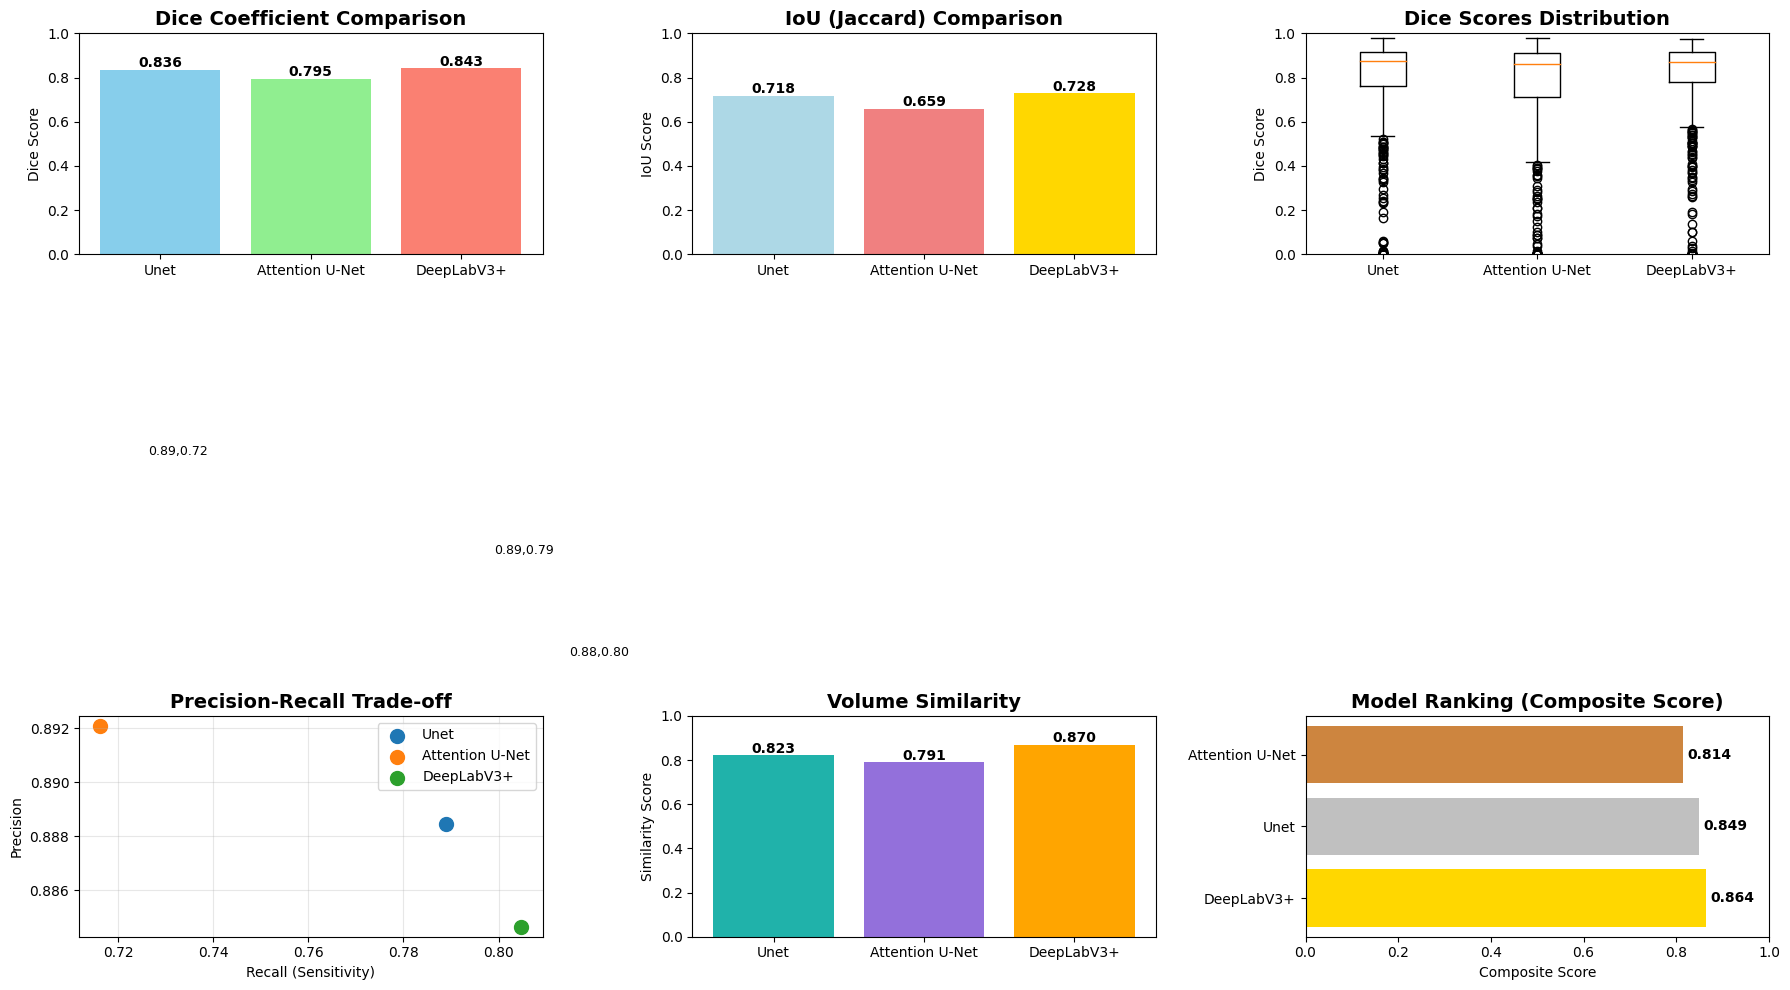


 Running comprehensive evaluation on ALL THREE MODELS...
COMPREHENSIVE MODEL COMPARISON - BRAIN MRI TUMOR SEGMENTATION

Evaluating: Unet
Original preprocessing, no augmentation

📊 PERFORMANCE SUMMARY - Unet
--------------------------------------------------

Core Segmentation Metrics:
  Dice Coefficient:    0.8358
  IoU (Jaccard):       0.7179
  F1-Score:            0.8358

Classification Metrics:
  Accuracy:            0.9934
  Precision:           0.8884
  Recall (Sensitivity): 0.7890
  Specificity:         0.9979

Sample-level Statistics (Dice):
  Mean ± Std:          0.7594 ± 0.2754
  Range:               [0.0000, 0.9785]

Volume Metrics:
  Avg Volume Diff:     289.2 pixels
  Volume Similarity:   0.8233

Confusion Matrix (pixels):
  True Positives:      940,672
  False Positives:     118,119
  False Negatives:     251,607
  True Negatives:      55,050,562

Evaluating: Attention U-Net
Z-score + edges, with attention mechanism

📊 PERFORMANCE SUMMARY - Attention U-Net
---------------

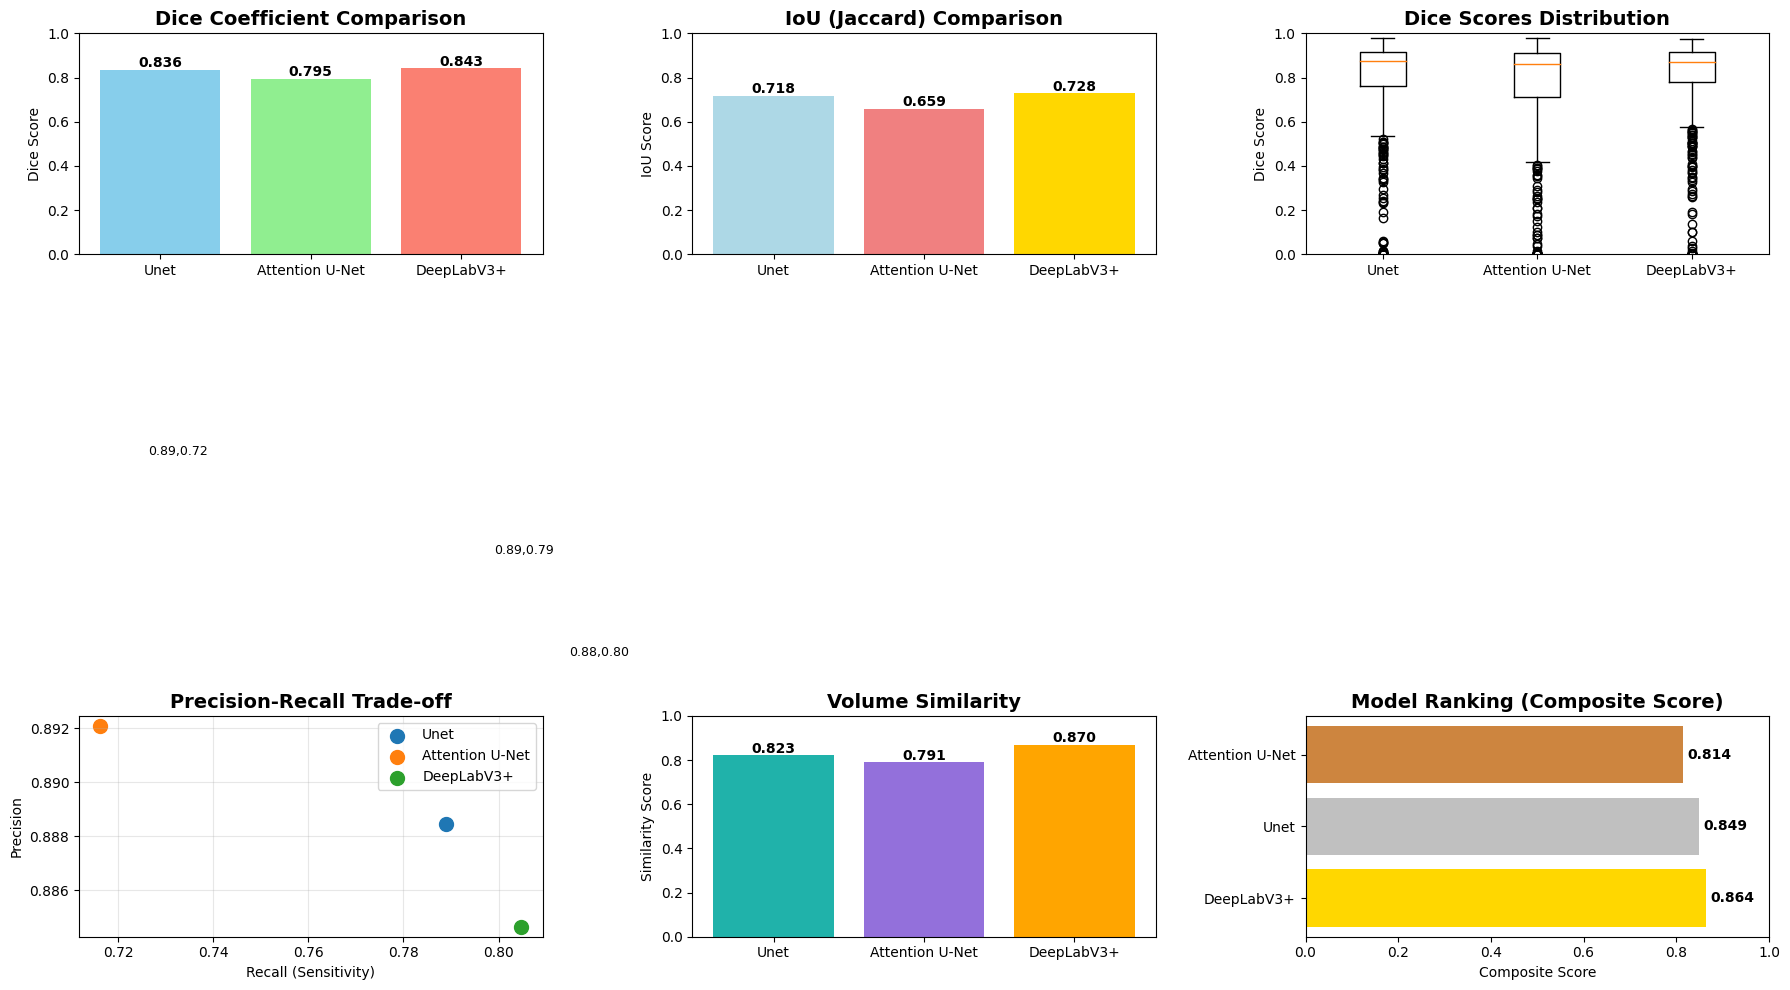

In [78]:
# Initialize comparator
comparator = SegmentationModelComparator(test_data=(X_test_z, Y_test_z))

# Add your models
comparator.add_model(
    name="Unet",
    model=unet,
    description="Original preprocessing, no augmentation"
)

comparator.add_model(
    name="Attention U-Net",
    model=att_unet,  # Your attention U-Net model
    description="Z-score + edges, with attention mechanism"
)

# ADD DEEPLAB HERE
comparator.add_model(
    name="DeepLabV3+",
    model=deeplab,  # Your DeepLab model
    description="Z-score + edges, DeepLabV3+ architecture"
)

# Run comprehensive evaluation on all three models
print("\n Running comprehensive evaluation on ALL THREE MODELS...")
results = comparator.evaluate_all()# ADD DEEPLAB HERE
comparator.add_model(
    name="DeepLabV3+",
    model=deeplab,  # Your DeepLab model
    description="Z-score + edges, DeepLabV3+ architecture"
)

# Run comprehensive evaluation on all three models
print("\n Running comprehensive evaluation on ALL THREE MODELS...")
results = comparator.evaluate_all()

